In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score, calinski_harabasz_score, davies_bouldin_score
from sklearn.decomposition import PCA
from sklearn.metrics import pairwise_distances

import iohclustering

In [2]:
FIDS = list(range(1, 11))
INSTANCES = [1]
K_VALUES = [2, 3, 5, 10]

RANDOM_SEED = 42
rng = np.random.default_rng(RANDOM_SEED)

# Next

In [8]:
def infer_dim(problem):
    """
    Infer the optimization dimension of an IOH/IOHClustering problem.

    For clustering, this dimension should usually correspond to:
        number_of_variables = k * data_feature_dimension

    because the candidate solution encodes k cluster centers.
    """
    md = getattr(problem, "meta_data", None)

    if md is not None and hasattr(md, "n_variables"):
        return int(md.n_variables)

    if hasattr(problem, "dimension"):
        return int(problem.dimension)

    bounds = getattr(problem, "bounds", None)

    if bounds is not None and hasattr(bounds, "lb"):
        return int(np.asarray(bounds.lb).size)

    return None

In [4]:
def get_bounds(problem):
    lb = np.asarray(problem.bounds.lb, dtype=float)
    ub = np.asarray(problem.bounds.ub, dtype=float)
    return lb, ub

In [5]:
def evaluate_problem(problem, x):
    """
    IOH problems are usually callable.
    """
    return float(problem(x))

In [11]:
def get_ioh_clustering_problem(fid, instance, k):
    problem, retransform = iohclustering.get_problem(
        fid=fid,
        instance=instance,
        k=k
    )
    return problem, retransform

# What's up

In [12]:
rows = []

for fid in FIDS:
    for instance in INSTANCES:
        for k in K_VALUES:
            problem, retransform = get_ioh_clustering_problem(
                fid=fid,
                instance=instance,
                k=k
            )

            dim = infer_dim(problem)
            lb, ub = get_bounds(problem)

            implied_feature_dim = dim / k if dim is not None else None

            rows.append({
                "fid": fid,
                "instance": instance,
                "k": k,
                "problem_name": str(problem),
                "optimization_dimension": dim,
                "implied_feature_dimension": implied_feature_dim,
                "lower_bound_min": lb.min(),
                "lower_bound_max": lb.max(),
                "upper_bound_min": ub.min(),
                "upper_bound_max": ub.max(),
                "search_space_width_mean": np.mean(ub - lb),
                "search_space_width_min": np.min(ub - lb),
                "search_space_width_max": np.max(ub - lb),
            })

structural_df = pd.DataFrame(rows)
structural_df

,fid,instance,k,problem_name,optimization_dimension,implied_feature_dimension,lower_bound_min,lower_bound_max,upper_bound_min,upper_bound_max,search_space_width_mean,search_space_width_min,search_space_width_max
0,1,1,2,<RealSingleObjectiveProblem 1. Cluster_breast_...,4,2.0,0.0,0.0,1.0,1.0,1.0,1.0,1.0
1,1,1,3,<RealSingleObjectiveProblem 1. Cluster_breast_...,6,2.0,0.0,0.0,1.0,1.0,1.0,1.0,1.0
2,1,1,5,<RealSingleObjectiveProblem 1. Cluster_breast_...,10,2.0,0.0,0.0,1.0,1.0,1.0,1.0,1.0
3,1,1,10,<RealSingleObjectiveProblem 1. Cluster_breast_...,20,2.0,0.0,0.0,1.0,1.0,1.0,1.0,1.0
4,2,1,2,<RealSingleObjectiveProblem 2. Cluster_diabete...,4,2.0,0.0,0.0,1.0,1.0,1.0,1.0,1.0
5,2,1,3,<RealSingleObjectiveProblem 2. Cluster_diabete...,6,2.0,0.0,0.0,1.0,1.0,1.0,1.0,1.0
6,2,1,5,<RealSingleObjectiveProblem 2. Cluster_diabete...,10,2.0,0.0,0.0,1.0,1.0,1.0,1.0,1.0
7,2,1,10,<RealSingleObjectiveProblem 2. Cluster_diabete...,20,2.0,0.0,0.0,1.0,1.0,1.0,1.0,1.0
8,3,1,2,<RealSingleObjectiveProblem 3. Cluster_german_...,4,2.0,0.0,0.0,1.0,1.0,1.0,1.0,1.0
9,3,1,3,<RealSingleObjectiveProblem 3. Cluster_german_...,6,2.0,0.0,0.0,1.0,1.0,1.0,1.0,1.0


## Sampling

In [14]:
def sample_random_objective_values(problem, n_samples=200, seed=42):
    rng = np.random.default_rng(seed)
    lb, ub = get_bounds(problem)
    dim = len(lb)
    
    values = []
    
    for _ in range(n_samples):
        x = rng.uniform(lb, ub, size=dim)
        y = evaluate_problem(problem, x)
        values.append(y)
    
    return np.asarray(values)

In [15]:
landscape_rows = []

for fid in FIDS:
    for instance in INSTANCES:
        for k in K_VALUES:
            problem, retransform = get_ioh_clustering_problem(
                fid=fid,
                instance=instance,
                k=k
            )
            dim = infer_dim(problem)
            
            values = sample_random_objective_values(
                problem,
                n_samples=300,
                seed=RANDOM_SEED + fid * 100 + k
            )
            
            landscape_rows.append({
                "fid": fid,
                "instance": instance,
                "k": k,
                "optimization_dimension": dim,
                "random_mse_min": np.min(values),
                "random_mse_mean": np.mean(values),
                "random_mse_std": np.std(values),
                "random_mse_median": np.median(values),
                "random_mse_q25": np.quantile(values, 0.25),
                "random_mse_q75": np.quantile(values, 0.75),
                "random_mse_cv": np.std(values) / np.mean(values) if np.mean(values) != 0 else np.nan,
            })

landscape_df = pd.DataFrame(landscape_rows)
landscape_df

,fid,instance,k,optimization_dimension,random_mse_min,random_mse_mean,random_mse_std,random_mse_median,random_mse_q25,random_mse_q75,random_mse_cv
0,1,1,2,4,0.056483,0.224105,0.153318,0.186663,0.103621,0.281927,0.684133
1,1,1,3,6,0.034217,0.162427,0.115092,0.125544,0.076890,0.208088,0.708575
2,1,1,5,10,0.026582,0.095779,0.064507,0.073345,0.050208,0.118924,0.673502
3,1,1,10,20,0.012478,0.045528,0.026987,0.038597,0.026979,0.054709,0.592759
4,2,1,2,4,0.034420,0.212036,0.179325,0.147200,0.077034,0.288523,0.845733
5,2,1,3,6,0.027107,0.162619,0.124784,0.131317,0.069714,0.223180,0.767337
6,2,1,5,10,0.016402,0.088502,0.067245,0.067562,0.042260,0.116975,0.759811
7,2,1,10,20,0.011199,0.048427,0.035556,0.038268,0.025059,0.059531,0.734208
8,3,1,2,4,0.036083,0.233881,0.178468,0.172739,0.097609,0.308259,0.763073
9,3,1,3,6,0.028237,0.179646,0.134982,0.135181,0.079191,0.242998,0.751382


## Distribution by K and by dim

C:\Users\Anna Michelle\AppData\Local\Temp\ipykernel_7236\4170162165.py:8: MatplotlibDeprecationWarning: The 'labels' parameter of boxplot() has been renamed 'tick_labels' since Matplotlib 3.9; support for the old name will be dropped in 3.11.
  ax.boxplot(data, labels=[f"k={k}" for k in K_VALUES])


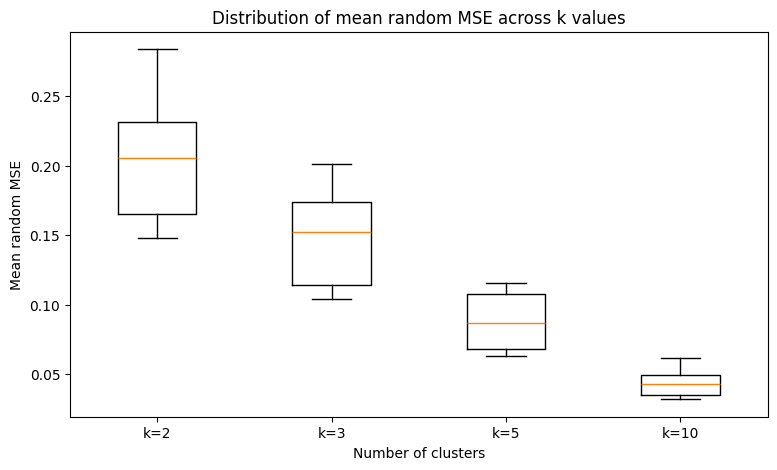

In [16]:
fig, ax = plt.subplots(figsize=(9, 5))

data = [
    landscape_df[landscape_df["k"] == k]["random_mse_mean"].values
    for k in K_VALUES
]

ax.boxplot(data, labels=[f"k={k}" for k in K_VALUES])
ax.set_xlabel("Number of clusters")
ax.set_ylabel("Mean random MSE")
ax.set_title("Distribution of mean random MSE across k values")
plt.show()

## Random Walk

In [18]:
def random_walk_autocorrelation(problem, n_steps=300, step_scale=0.05, seed=42):
    rng = np.random.default_rng(seed)
    lb, ub = get_bounds(problem)
    dim = len(lb)
    width = ub - lb
    
    x = rng.uniform(lb, ub, size=dim)
    values = []
    
    for _ in range(n_steps):
        values.append(evaluate_problem(problem, x))
        
        step = rng.normal(0, step_scale, size=dim) * width
        x = np.clip(x + step, lb, ub)
    
    values = np.asarray(values)
    
    if np.std(values[:-1]) == 0 or np.std(values[1:]) == 0:
        return np.nan
    
    return np.corrcoef(values[:-1], values[1:])[0, 1]

In [19]:
ruggedness_rows = []

for fid in FIDS:
    for instance in INSTANCES:
        for k in K_VALUES:
            problem, retransform = get_ioh_clustering_problem(
                fid=fid,
                instance=instance,
                k=k
            )
            dim = infer_dim(problem)
            
            autocorr = random_walk_autocorrelation(
                problem,
                n_steps=400,
                step_scale=0.03,
                seed=RANDOM_SEED + fid * 100 + k
            )
            
            ruggedness_rows.append({
                "fid": fid,
                "instance": instance,
                "k": k,
                "optimization_dimension": dim,
                "random_walk_autocorrelation": autocorr,
                "ruggedness_proxy": 1 - autocorr if not np.isnan(autocorr) else np.nan,
            })

ruggedness_df = pd.DataFrame(ruggedness_rows)
ruggedness_df

,fid,instance,k,optimization_dimension,random_walk_autocorrelation,ruggedness_proxy
0,1,1,2,4,0.952010,0.047990
1,1,1,3,6,0.981621,0.018379
2,1,1,5,10,0.969182,0.030818
3,1,1,10,20,0.962546,0.037454
4,2,1,2,4,0.963045,0.036955
5,2,1,3,6,0.954982,0.045018
6,2,1,5,10,0.980164,0.019836
7,2,1,10,20,0.940333,0.059667
8,3,1,2,4,0.951203,0.048797
9,3,1,3,6,0.931903,0.068097


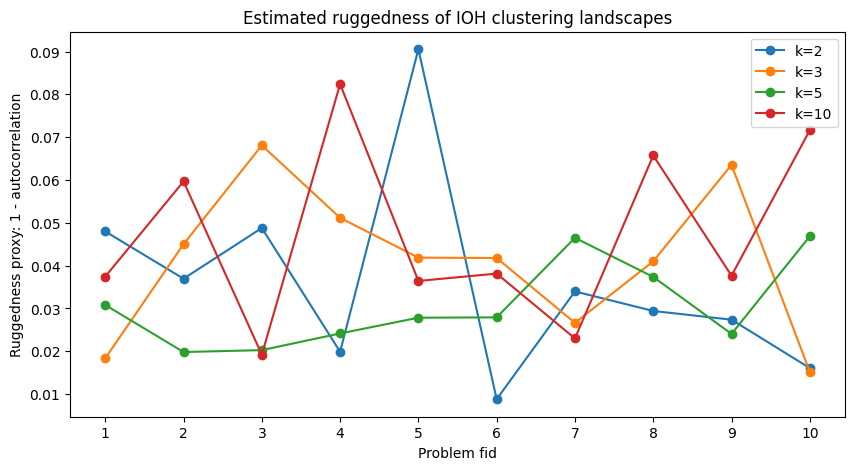

In [21]:
fig, ax = plt.subplots(figsize=(10, 5))

for k in K_VALUES:
    subset = ruggedness_df[ruggedness_df["k"] == k]
    ax.plot(
        subset["fid"],
        subset["ruggedness_proxy"],
        marker="o",
        label=f"k={k}"
    )

ax.set_xlabel("Problem fid")
ax.set_xticks(FIDS)
ax.set_ylabel("Ruggedness proxy: 1 - autocorrelation")
ax.set_title("Estimated ruggedness of IOH clustering landscapes")
ax.legend()
plt.show()

## Local Sensitivity 

In [22]:
def local_sensitivity(problem, n_points=50, n_neighbors=20, perturbation_scale=0.01, seed=42):
    rng = np.random.default_rng(seed)
    lb, ub = get_bounds(problem)
    dim = len(lb)
    width = ub - lb
    
    sensitivities = []
    
    for _ in range(n_points):
        x = rng.uniform(lb, ub, size=dim)
        fx = evaluate_problem(problem, x)
        
        neighbor_values = []
        
        for _ in range(n_neighbors):
            noise = rng.normal(0, perturbation_scale, size=dim) * width
            x_neighbor = np.clip(x + noise, lb, ub)
            f_neighbor = evaluate_problem(problem, x_neighbor)
            neighbor_values.append(abs(f_neighbor - fx))
        
        sensitivities.append(np.mean(neighbor_values))
    
    return np.mean(sensitivities), np.std(sensitivities)

In [23]:
sensitivity_rows = []

for fid in FIDS:
    for instance in INSTANCES:
        for k in K_VALUES:
            problem, retransform = get_ioh_clustering_problem(
                fid=fid,
                instance=instance,
                k=k
            )
            dim = infer_dim(problem)
            
            mean_sens, std_sens = local_sensitivity(
                problem,
                n_points=40,
                n_neighbors=20,
                perturbation_scale=0.01,
                seed=RANDOM_SEED + fid * 100 + k
            )
            
            sensitivity_rows.append({
                "fid": fid,
                "instance": instance,
                "k": k,
                "optimization_dimension": dim,
                "local_sensitivity_mean": mean_sens,
                "local_sensitivity_std": std_sens,
            })

sensitivity_df = pd.DataFrame(sensitivity_rows)
sensitivity_df

,fid,instance,k,optimization_dimension,local_sensitivity_mean,local_sensitivity_std
0,1,1,2,4,0.004809,0.003347
1,1,1,3,6,0.003207,0.001701
2,1,1,5,10,0.002164,0.001242
3,1,1,10,20,0.001318,0.000700
4,2,1,2,4,0.005855,0.003561
5,2,1,3,6,0.004270,0.002876
6,2,1,5,10,0.002696,0.001561
7,2,1,10,20,0.001862,0.001519
8,3,1,2,4,0.005869,0.002977
9,3,1,3,6,0.004073,0.002027


## Everything we have recorded 

In [28]:
properties_df = (
    structural_df
    .merge(
        landscape_df,
        on=["fid", "instance", "k", "optimization_dimension"],
        how="left"
    )
    .merge(
        ruggedness_df,
        on=["fid", "instance", "k", "optimization_dimension"],
        how="left"
    )
    .merge(
        sensitivity_df,
        on=["fid", "instance", "k", "optimization_dimension"],
        how="left"
    )
)

properties_df

,fid,instance,k,problem_name,optimization_dimension,implied_feature_dimension,lower_bound_min,lower_bound_max,upper_bound_min,upper_bound_max,...,random_mse_mean,random_mse_std,random_mse_median,random_mse_q25,random_mse_q75,random_mse_cv,random_walk_autocorrelation,ruggedness_proxy,local_sensitivity_mean,local_sensitivity_std
0,1,1,2,<RealSingleObjectiveProblem 1. Cluster_breast_...,4,2.0,0.0,0.0,1.0,1.0,...,0.224105,0.153318,0.186663,0.103621,0.281927,0.684133,0.952010,0.047990,0.004809,0.003347
1,1,1,3,<RealSingleObjectiveProblem 1. Cluster_breast_...,6,2.0,0.0,0.0,1.0,1.0,...,0.162427,0.115092,0.125544,0.076890,0.208088,0.708575,0.981621,0.018379,0.003207,0.001701
2,1,1,5,<RealSingleObjectiveProblem 1. Cluster_breast_...,10,2.0,0.0,0.0,1.0,1.0,...,0.095779,0.064507,0.073345,0.050208,0.118924,0.673502,0.969182,0.030818,0.002164,0.001242
3,1,1,10,<RealSingleObjectiveProblem 1. Cluster_breast_...,20,2.0,0.0,0.0,1.0,1.0,...,0.045528,0.026987,0.038597,0.026979,0.054709,0.592759,0.962546,0.037454,0.001318,0.000700
4,2,1,2,<RealSingleObjectiveProblem 2. Cluster_diabete...,4,2.0,0.0,0.0,1.0,1.0,...,0.212036,0.179325,0.147200,0.077034,0.288523,0.845733,0.963045,0.036955,0.005855,0.003561
5,2,1,3,<RealSingleObjectiveProblem 2. Cluster_diabete...,6,2.0,0.0,0.0,1.0,1.0,...,0.162619,0.124784,0.131317,0.069714,0.223180,0.767337,0.954982,0.045018,0.004270,0.002876
6,2,1,5,<RealSingleObjectiveProblem 2. Cluster_diabete...,10,2.0,0.0,0.0,1.0,1.0,...,0.088502,0.067245,0.067562,0.042260,0.116975,0.759811,0.980164,0.019836,0.002696,0.001561
7,2,1,10,<RealSingleObjectiveProblem 2. Cluster_diabete...,20,2.0,0.0,0.0,1.0,1.0,...,0.048427,0.035556,0.038268,0.025059,0.059531,0.734208,0.940333,0.059667,0.001862,0.001519
8,3,1,2,<RealSingleObjectiveProblem 3. Cluster_german_...,4,2.0,0.0,0.0,1.0,1.0,...,0.233881,0.178468,0.172739,0.097609,0.308259,0.763073,0.951203,0.048797,0.005869,0.002977
9,3,1,3,<RealSingleObjectiveProblem 3. Cluster_german_...,6,2.0,0.0,0.0,1.0,1.0,...,0.179646,0.134982,0.135181,0.079191,0.242998,0.751382,0.931903,0.068097,0.004073,0.002027


## Fitness by algorithm

In [1]:
import pandas as pd
from iohblade.loggers import ExperimentLogger
#from iohblade.plots import plot_convergence, plot_experiment_CEG,plot_speedup, plot_code_evolution_graphs, plot_boxplot_fitness, plot_boxplot_fitness_hue, plot_token_usage, fitness_table, plotly_code_evolution
logger = ExperimentLogger(name='results\mutation_5_runs_elitism_off_16', read=True)

# registered_exp = logger.add_read_dir('results/Results_compare_KMeans_changed_Task_Prompt_to_be_Diverse(only one type of Alg)')
# df = logger.get_methods_problems()
# # print(df)
# df = logger.get_data()
# print(df[["method_name", "problem_name", "log_dir", "seed"]])
df = logger.get_problem_data("CLUSTERING")
print(type(df))
# print(df)
# df = pd.read_json('results/Results_compare_KMeans_changed_Task_Prompt_to_be_Diverse(only one type of Alg)/run-LLaMEA-CLUSTERING-0/log.jsonl', lines=True)
# print(df)


<class 'pandas.DataFrame'>


ES: 29
DE: 314
PSO: 143
Other: 0
DE+MA: 0
MA: 301
SA: 0


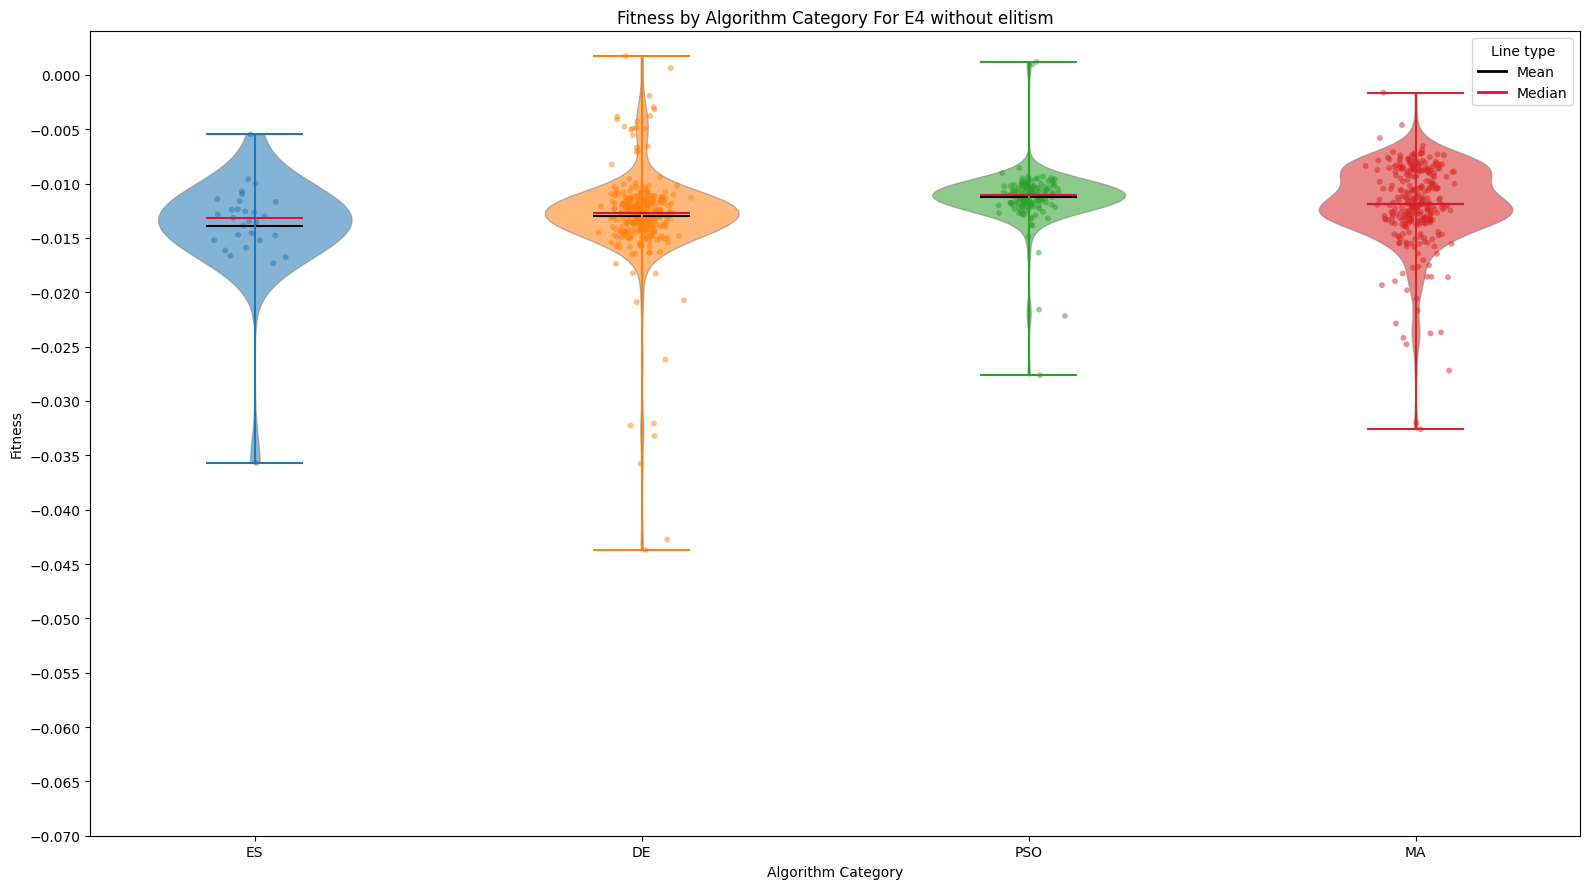

In [3]:
import pandas as pd
import matplotlib.pyplot as plt
import numpy as np


def classify_algorithm(name: str, description: str = None) -> str:
    if pd.isna(name):
        return "Other"

    n = str(name).strip().upper()
    desc = str(description).strip().upper() if description and not pd.isna(description) else ""

    explicit_map = {
        "HYBRIDDELOCALSEARCH": "ES",
        "CLUSTERINGHYBRIDOPTIMIZER": "DE",
        "CHAOSENHANCEDCLUSTERINGOPTIMIZER": "DE",
        "ADAPTIVECHAOTICCLUSTERINGOPTIMIZER": "DE",
        "ENTROPYDRIVENCLUSTERINGOPTIMIZER": "DE",
        "CHAOTICHYBRIDCLUSTERINGOPTIMIZER": "DE",
        "HYBRIDCLUSTERINGOPTIMIZER": "DE",
        "ADAPTIVEESCLUSTERING": "ES",
        "ADAPTIVEPSOCLUSTERING": "PSO",
        "ADAPTIVEMULTISWARMCLUSTERING": "PSO",
        "ADAPTIVECLUSTERINGEA": "ES",
        "ECA": "ES",
    }

    if n in explicit_map:
        return explicit_map[n]

    # Simulated Annealing — check name first, then description
    if "SIMULATED" in n or "ANNEALING" in n or "SA" == n:
        return "SA"
    if "SIMULATED ANNEALING" in desc or "ANNEALING" in desc:
        return "SA"

    if "PSO" in n or "SWARM" in n:
        return "PSO"

    if "UMDA" in n or "EDA" in n:
        return "EDA"

    # DE + Memetic combos: name contains DE signals AND local search signals
    de_signal = "DE" in n or "DIFFERENTIAL" in n
    local_search_signal = (
        "MEMETIC" in n or "LOCAL" in n or "LOCAL SEARCH" in desc
        or "LOCAL-SEARCH" in desc or "MEMETIC" in desc
    )

    if de_signal and local_search_signal:
        return "DE"

    if de_signal:
        return "DE"

    # Pure memetic: name says memetic, or description mentions local search
    if "MEMETIC" in n or local_search_signal:
        return "MA"

    if "EA" in n or "EVOLUTIONARY" in n or "ES" in n or "ECA" in n or "ADAPTIVECLUSTERING" in n:
        return "ES"

    return "ES"


# Pass description column if available
if "description" in df.columns:
    df["algorithm_category"] = df.apply(
        lambda r: classify_algorithm(r["name"], r.get("description")), axis=1
    )
else:
    df["algorithm_category"] = df["name"].apply(classify_algorithm)

categories = ["ES", "DE", "PSO", "Other", "DE+MA", "MA", "SA"]
df_plot = df[df["algorithm_category"].isin(categories)].copy()

data = []
categories_with_data = []
def remove_outliers_iqr(series: pd.Series) -> pd.Series:
    q1 = series.quantile(0.25)
    q3 = series.quantile(0.75)
    iqr = q3 - q1
    lower = q1 - 1.5 * iqr
    upper = q3 + 1.5 * iqr
    return series[(series >= lower) & (series <= upper)]

for cat in categories:
    d = df_plot.loc[
        (df_plot["algorithm_category"] == cat) &
        (df_plot["fitness"] >= -1),
        "fitness"
    ].dropna()

    # Remove outliers
    # d = remove_outliers_iqr(d)

    if not d.empty:
        data.append(d)
        categories_with_data.append(cat)

for cat in categories:
    d = df_plot.loc[
        (df_plot["algorithm_category"] == cat) &
        (df_plot["fitness"] >= -1),
        "fitness"
    ].dropna()
    print(f"{cat}: {len(d)}")

if data:
    plt.figure(figsize=(16, 9))

    # Extend palette to cover up to 8 categories
    palette = ["C0", "C1", "C2", "C3", "C4", "C5", "C6", "C7"]
    colors = palette[:len(categories_with_data)]

    for i, (d, cat) in enumerate(zip(data, categories_with_data), start=1):
        vp = plt.violinplot(
            d,
            positions=[i],
            showmeans=True,
            showmedians=True
        )

        for pc in vp["bodies"]:
            pc.set_facecolor(colors[i - 1])
            pc.set_edgecolor("gray")
            pc.set_alpha(0.55)

        vp["cmeans"].set_color("black")
        vp["cmedians"].set_color("crimson")

        y = d.values
        x = np.random.normal(i, 0.04, size=len(y))

        plt.scatter(
            x, y,
            alpha=0.5,
            s=18,
            color=colors[i - 1],
            edgecolors="none"
        )

    plt.xticks(
        range(1, len(categories_with_data) + 1),
        categories_with_data
    )

    mean_line = plt.Line2D([], [], color="black", linewidth=2, label="Mean")
    median_line = plt.Line2D([], [], color="crimson", linewidth=2, label="Median")
    plt.legend(handles=[mean_line, median_line], title="Line type")

    plt.title("Fitness by Algorithm Category For E4 without elitism")
    plt.xlabel("Algorithm Category")
    plt.ylabel("Fitness")
    plt.yticks(np.arange(-0.07, 0.004, 0.005))
    # plt.ylim(bottom=-0.044)
    plt.tight_layout()
    plt.show()

In [ ]:
# Ground truth: what does the classifier actually assign each name?
if "description" in df.columns:
    df["algorithm_category"] = df.apply(
        lambda r: classify_algorithm(r["name"], r.get("description")), axis=1
    )
else:
    df["algorithm_category"] = df["name"].apply(classify_algorithm)

# Now count from the already-assigned column, not by re-calling the classifier
print(df["algorithm_category"].value_counts())

sum = 0

for cat, grp in df.groupby("algorithm_category"):
    sum += len(grp)

print(f"Total {sum}") 


# ── Audit: fitness filter drops ──────────────────────────────────────────
print(f"\nTotal rows in df:             {len(df)}")

nan_mask    = df["fitness"].isna()
neginf_mask = df["fitness"] == -np.inf
neg1e9_mask = df["fitness"] == -1e9
other_bad   = (df["fitness"] < -1) & ~neginf_mask & ~neg1e9_mask & ~nan_mask

print(f"Dropped — NaN fitness:        {nan_mask.sum()}")
print(f"Dropped — -inf fitness:       {neginf_mask.sum()}")
print(f"Dropped — -1e9 fitness:       {neg1e9_mask.sum()}")
print(f"Dropped — other < -1:         {other_bad.sum()}")
print(f"Total dropped by filter:      {(nan_mask | (df['fitness'] < -1)).sum()}")
print(f"Remaining after filter:       {((df['fitness'] >= -1) & ~nan_mask).sum()}")

print("\n── Per-category drop breakdown ──")
for cat, grp in df.groupby("algorithm_category"):
    n_nan       = grp["fitness"].isna().sum()
    n_neginf    = (grp["fitness"] == -np.inf).sum()
    n_neg1e9    = (grp["fitness"] == -1e9).sum()
    n_other_bad = ((grp["fitness"] < -1) & (grp["fitness"] != -np.inf) & (grp["fitness"] != -1e9) & grp["fitness"].notna()).sum()
    n_kept      = ((grp["fitness"] >= -1) & grp["fitness"].notna()).sum()
    print(f"{cat:8s}  total={len(grp):4d}  kept={n_kept:4d}  "
          f"nan={n_nan:3d}  -inf={n_neginf:3d}  -1e9={n_neg1e9:3d}  other<-1={n_other_bad:3d}")

algorithm_category
DE     402
MA     366
PSO    158
ES      50
Name: count, dtype: int64
Total 976

Total rows in df:             976
Dropped — NaN fitness:        0
Dropped — -inf fitness:       132
Dropped — -1e9 fitness:       25
Dropped — other < -1:         32
Total dropped by filter:      189
Remaining after filter:       787

── Per-category drop breakdown ──
DE        total= 402  kept= 314  nan=  0  -inf= 67  -1e9=  7  other<-1= 14
ES        total=  50  kept=  29  nan=  0  -inf=  9  -1e9=  3  other<-1=  9
MA        total= 366  kept= 301  nan=  0  -inf= 48  -1e9= 10  other<-1=  7
PSO       total= 158  kept= 143  nan=  0  -inf=  8  -1e9=  5  other<-1=  2


: 

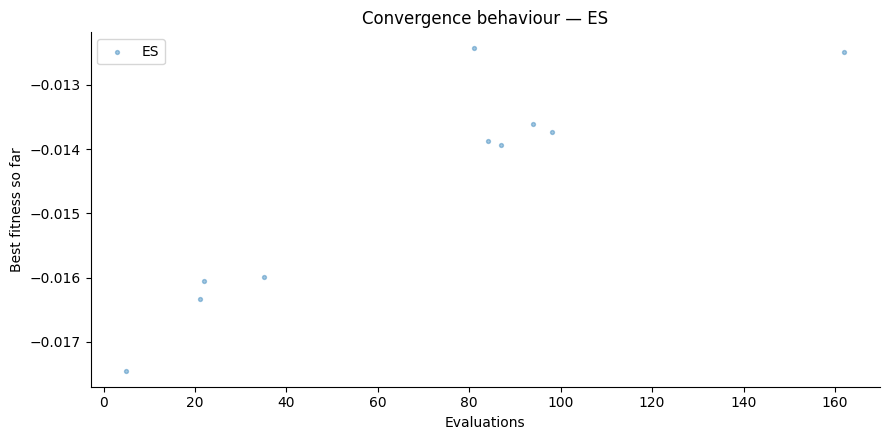

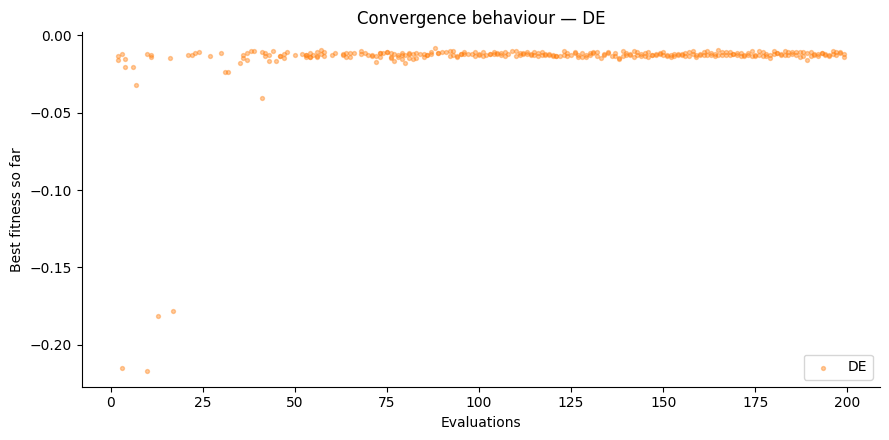

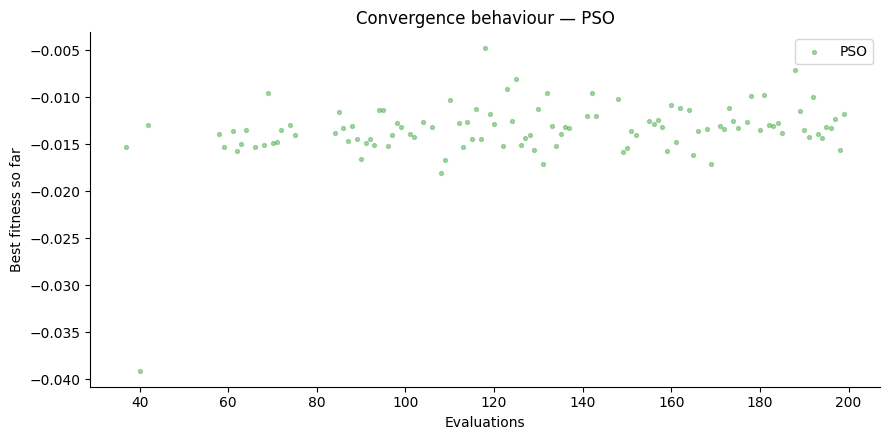

No data for Other, skipping


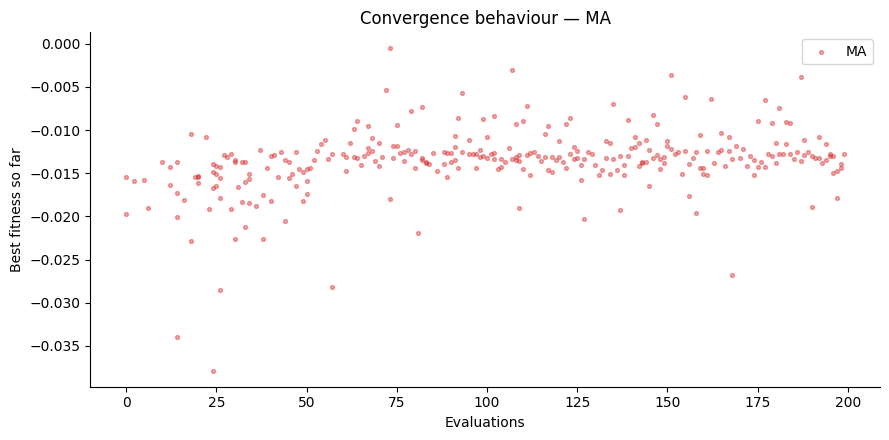

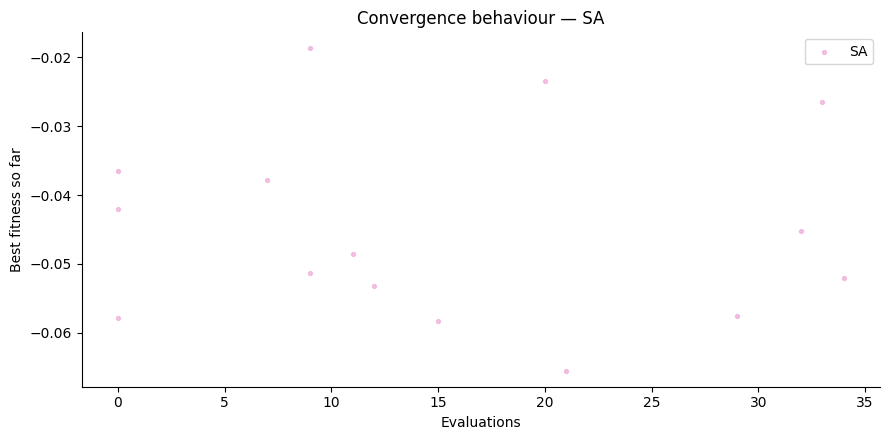

In [73]:
import numpy as np
import pandas as pd

df = logger.get_problem_data("CLUSTERING")

df["best_so_far"] = df.groupby(["name", "id"])["fitness"].cummax()

import matplotlib.pyplot as plt


def classify_algorithm(name: str, description: str = None) -> str:
    if pd.isna(name):
        return "Other"

    n = str(name).strip().upper()
    desc = str(description).strip().upper() if description and not pd.isna(description) else ""

    explicit_map = {
        "HYBRIDDELOCALSEARCH": "ES",
        "CLUSTERINGHYBRIDOPTIMIZER": "DE",
        "CHAOSENHANCEDCLUSTERINGOPTIMIZER": "DE",
        "ADAPTIVECHAOTICCLUSTERINGOPTIMIZER": "DE",
        "ENTROPYDRIVENCLUSTERINGOPTIMIZER": "DE",
        "CHAOTICHYBRIDCLUSTERINGOPTIMIZER": "DE",
        "HYBRIDCLUSTERINGOPTIMIZER": "DE",
        "ADAPTIVEESCLUSTERING": "ES",
        "ADAPTIVEPSOCLUSTERING": "PSO",
        "ADAPTIVEMULTISWARMCLUSTERING": "PSO",
        "ADAPTIVECLUSTERINGEA": "ES",
        "ECA": "ES",
    }

    if n in explicit_map:
        return explicit_map[n]

    # Simulated Annealing — check name first, then description
    if "SIMULATED" in n or "ANNEALING" in n or "SA" == n:
        return "SA"
    if "SIMULATED ANNEALING" in desc or "ANNEALING" in desc:
        return "SA"

    if "PSO" in n or "SWARM" in n:
        return "PSO"

    if "UMDA" in n or "EDA" in n:
        return "EDA"

    # DE + Memetic combos: name contains DE signals AND local search signals
    de_signal = "DE" in n or "DIFFERENTIAL" in n
    local_search_signal = (
        "MEMETIC" in n or "LOCAL" in n or "LOCAL SEARCH" in desc
        or "LOCAL-SEARCH" in desc or "MEMETIC" in desc
    )

    if de_signal and local_search_signal:
        return "DE"

    if de_signal:
        return "DE"

    # Pure memetic: name says memetic, or description mentions local search
    if "MEMETIC" in n or local_search_signal:
        return "MA"

    if "EA" in n or "EVOLUTIONARY" in n or "ES" in n or "ECA" in n or "ADAPTIVECLUSTERING" in n:
        return "ES"

    return "ES"


# Pass description column if available
if "description" in df.columns:
    df["algorithm_category"] = df.apply(
        lambda r: classify_algorithm(r["name"], r.get("description")), axis=1
    )
else:
    df["algorithm_category"] = df["name"].apply(classify_algorithm)

categories = ["ES", "DE", "PSO", "Other", "MA", "SA"]
df_plot = df[df["algorithm_category"].isin(categories)].copy()

df_plot = df_plot[np.isfinite(df_plot["best_so_far"])]
df_plot = df_plot[~np.isclose(df_plot["best_so_far"], -1e9, atol=1e6)]
df_plot = df_plot[df_plot["best_so_far"] >= -1]

color_map = {
    "ES": "tab:blue",
    "DE":  "tab:orange",
    "PSO":   "tab:green",
    "Other": "tab:gray",
    "MA": "tab:red",
    "SA": "tab:pink",
}

for alg in ["ES", "DE", "PSO", "Other", "MA", "SA"]:
    subset = df_plot[df_plot["algorithm_category"] == alg]
    if subset.empty:
        print(f"No data for {alg}, skipping")
        continue

    plt.figure(figsize=(9, 4.5))
    plt.scatter(
        subset["_id"],
        subset["best_so_far"],
        label=alg,
        color=color_map.get(alg, "tab:gray"),
        s=8,
        alpha=0.4,
    )

    plt.xlabel("Evaluations")
    plt.ylabel("Best fitness so far")
    plt.title(f"Convergence behaviour — {alg}")
    plt.legend()
    plt.gca().spines["top"].set_visible(False)
    plt.gca().spines["right"].set_visible(False)
    plt.tight_layout()
    plt.show()

In [74]:
# All unique algorithm names and their counts
algo_counts = df["name"].value_counts().reset_index()
algo_counts.columns = ["name", "count"]

# Add the category each name maps to
if "description" in df.columns:
    algo_counts["category"] = algo_counts["name"].apply(
        lambda n: classify_algorithm(n, df.loc[df["name"] == n, "description"].iloc[0])
    )
else:
    algo_counts["category"] = algo_counts["name"].apply(classify_algorithm)

print(f"Total unique algorithm names: {len(algo_counts)}")
print(f"Total rows: {len(df)}\n")
print(algo_counts.to_string(index=False))

Total unique algorithm names: 47
Total rows: 1000

                                       name  count category
                  HybridClusteringOptimizer    193       DE
          AdaptiveHybridClusteringOptimizer    166       MA
                    SpectralHybridOptimizer    156       MA
                      AdaptiveClusteringPSO    134      PSO
                   AdaptiveChaosDEOptimizer    129       DE
                       ClusteringAdaptiveDE     43       DE
        GradientAdaptiveRestartOptimization     25       MA
       AdaptiveSimulatedAnnealingClustering     20       SA
      AdaptiveMultiStartClusteringOptimizer     18       MA
    AdaptiveDifferentialEvolutionClustering     18       DE
                    ChaosEnhancedAdaptiveDE     16      EDA
             ClusteringAwareHybridOptimizer      9       MA
                AdaptiveClusteringOptimizer      9       MA
   DifferentialEvolutionWithLocalRefinement      6       DE
                AdaptiveClusteringEvolution      

In [19]:
%pip uninstall codebleu tree-sitter tree-sitter-python
%pip install codebleu==0.7.1 tree-sitter==0.22.3 tree-sitter-python==0.21.0

^C
Note: you may need to restart the kernel to use updated packages.
Note: you may need to restart the kernel to use updated packages.


ERROR: Could not find a version that satisfies the requirement codebleu==0.7.1 (from versions: 0.0.1, 0.0.2, 0.1.2, 0.1.4, 0.1.5, 0.1.7, 0.2.0, 0.2.1, 0.3.0, 0.4.0, 0.5.0, 0.6.0, 0.6.1, 0.7.0)
ERROR: No matching distribution found for codebleu==0.7.1


In [1]:
import pandas as pd
from iohblade.loggers import ExperimentLogger
# from iohblade.plots import plot_convergence, plot_experiment_CEG,plot_speedup, plot_code_evolution_graphs, plot_boxplot_fitness, plot_boxplot_fitness_hue, plot_token_usage, fitness_table, plotly_code_evolution
logger = ExperimentLogger(name='results\mutation_5_runs_elitism_off_16', read=True)

# registered_exp = logger.add_read_dir('results/Results_compare_KMeans_changed_Task_Prompt_to_be_Diverse(only one type of Alg)')
# df = logger.get_methods_problems()
# # print(df)
# df = logger.get_data()
# print(df[["method_name", "problem_name", "log_dir", "seed"]])
df = logger.get_problem_data("CLUSTERING")
print(type(df))
# print(df)
# df = pd.read_json('results/Results_compare_KMeans_changed_Task_Prompt_to_be_Diverse(only one type of Alg)/run-LLaMEA-CLUSTERING-0/log.jsonl', lines=True)
# print(df)


<class 'pandas.DataFrame'>


In [2]:
import pandas as pd
from iohblade.loggers import ExperimentLogger

EXPS_TO_COMBINE = {
    "E3: Mutation w/o Elitism":   "results/mutation_5_runs_elitism_off_16",
    "E5: Mutation + Elitism":     "results/mutation_5_runs_elitism_on",
    "E4: Warm Start w/o Elitism": "results/warm_start_5_runs_elistism_off_16_child",
    "E6: Warm Start + Elitism":   "results/warm_start_5_runs",
}

dfs = []
for exp_label, result_dir in EXPS_TO_COMBINE.items():
    logger = ExperimentLogger(name=result_dir, read=True)
    exp_df = logger.get_problem_data("CLUSTERING")
    exp_df["source_experiment"] = exp_label
    dfs.append(exp_df)
    print(f"{exp_label}: {len(exp_df)} rows")

df = pd.concat(dfs, ignore_index=True)
print(f"\nCombined df: {len(df)} rows")
print(df["source_experiment"].value_counts())

E3: Mutation w/o Elitism: 976 rows
E5: Mutation + Elitism: 1000 rows
E4: Warm Start w/o Elitism: 1000 rows
E6: Warm Start + Elitism: 1000 rows

Combined df: 3976 rows
source_experiment
E5: Mutation + Elitism        1000
E4: Warm Start w/o Elitism    1000
E6: Warm Start + Elitism      1000
E3: Mutation w/o Elitism       976
Name: count, dtype: int64


In [3]:
def classify_algorithm(name: str, description: str = None) -> str:
    if pd.isna(name):
        return "Other"

    n = str(name).strip().upper()
    desc = str(description).strip().upper() if description and not pd.isna(description) else ""

    explicit_map = {
        "HYBRIDDELOCALSEARCH": "ES",
        "CLUSTERINGHYBRIDOPTIMIZER": "DE",
        "CHAOSENHANCEDCLUSTERINGOPTIMIZER": "DE",
        "ADAPTIVECHAOTICCLUSTERINGOPTIMIZER": "DE",
        "ENTROPYDRIVENCLUSTERINGOPTIMIZER": "DE",
        "CHAOTICHYBRIDCLUSTERINGOPTIMIZER": "DE",
        "HYBRIDCLUSTERINGOPTIMIZER": "DE",
        "ADAPTIVEESCLUSTERING": "ES",
        "ADAPTIVEPSOCLUSTERING": "PSO",
        "ADAPTIVEMULTISWARMCLUSTERING": "PSO",
        "ADAPTIVECLUSTERINGEA": "ES",
        "ECA": "ES",
    }

    if n in explicit_map:
        return explicit_map[n]

    # Simulated Annealing — check name first, then description
    if "SIMULATED" in n or "ANNEALING" in n or "SA" == n:
        return "SA"
    if "SIMULATED ANNEALING" in desc or "ANNEALING" in desc:
        return "SA"

    if "PSO" in n or "SWARM" in n:
        return "PSO"

    if "UMDA" in n or "EDA" in n:
        return "EDA"

    # DE + Memetic combos: name contains DE signals AND local search signals
    de_signal = "DE" in n or "DIFFERENTIAL" in n
    local_search_signal = (
        "MEMETIC" in n or "LOCAL" in n or "LOCAL SEARCH" in desc
        or "LOCAL-SEARCH" in desc or "MEMETIC" in desc
    )

    if de_signal and local_search_signal:
        return "DE"

    if de_signal:
        return "DE"

    # Pure memetic: name says memetic, or description mentions local search
    if "MEMETIC" in n or local_search_signal:
        return "MA"

    if "EA" in n or "EVOLUTIONARY" in n or "ES" in n or "ECA" in n or "ADAPTIVECLUSTERING" in n:
        return "ES"

    return "ES"


# Pass description column if available
if "description" in df.columns:
    df["algorithm_category"] = df.apply(
        lambda r: classify_algorithm(r["name"], r.get("description")), axis=1
    )
else:
    df["algorithm_category"] = df["name"].apply(classify_algorithm)

categories = ["ES", "DE", "PSO", "Other", "DE+MA", "MA", "SA"]
df_plot = df[df["algorithm_category"].isin(categories)].copy()

Unique algorithms for CodeBLEU: 35
category
MA     18
DE     14
ES      1
PSO     1
SA      1
Name: count, dtype: int64


CodeBLEU:   0%|          | 0/595 [00:00<?, ?it/s]

CodeBLEU: 100%|██████████| 595/595 [00:59<00:00,  9.96it/s]



Category-pair CodeBLEU matrix:
           DE        ES        MA       PSO        SA
DE   0.354817  0.254920  0.321905  0.270155  0.241276
ES   0.254920       NaN  0.312516  0.409465  0.194265
MA   0.321905  0.312516  0.341841  0.292700  0.280141
PSO  0.270155  0.409465  0.292700       NaN  0.237064
SA   0.241276  0.194265  0.280141  0.237064       NaN


TypeError: 'int' object is not callable

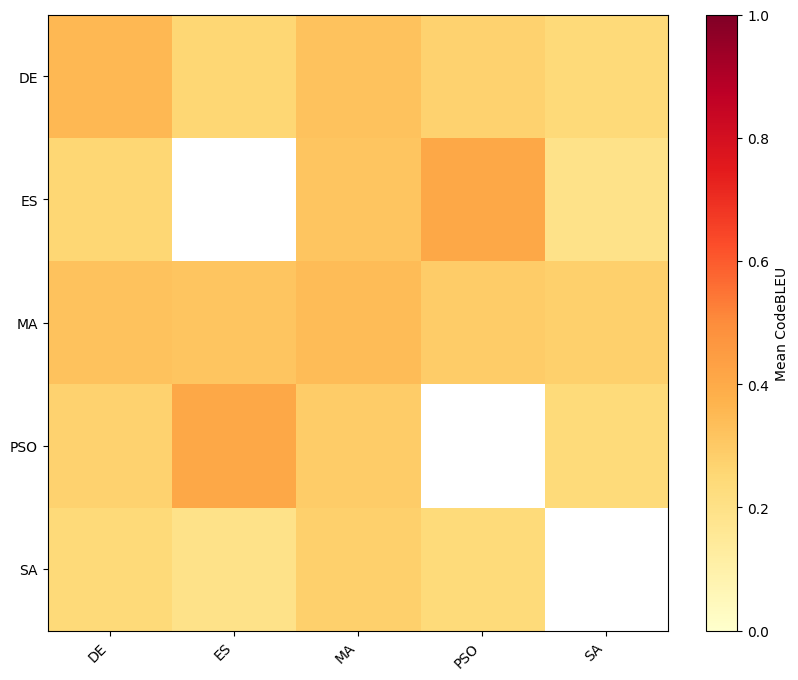

In [75]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.colors as mcolors
from codebleu import calc_codebleu
from itertools import combinations
from tqdm import tqdm

def compute_codebleu(code_a: str, code_b: str) -> float:
    if not isinstance(code_a, str) or not isinstance(code_b, str):
        return np.nan
    if not code_a.strip() or not code_b.strip():
        return np.nan
    try:
        result = calc_codebleu(
            references=[code_a],
            predictions=[code_b],
            lang="python",
            weights=(0.33, 0.33, 0.34, 0.0),  # ngram, weighted_ngram, syntax — no dataflow
        )
        return result["codebleu"]
    except Exception as e:
        return np.nan
    
# ── 1. Build a clean per-algorithm table ─────────────────────────────────
# One row per unique algorithm: take the first code/description/best fitness
algo_df = (
    df_plot[df_plot["code"].notna() & df_plot["algorithm_category"].notna()]
    .groupby("name")
    .agg(
        code=("code", "first"),
        description=("description", "first") if "description" in df_plot.columns else ("code", "first"),
        category=("algorithm_category", "first"),
        best_fitness=("fitness", "max"),   # best (highest) fitness seen
        mean_fitness=("fitness", "mean"),
    )
    .reset_index()
)

print(f"Unique algorithms for CodeBLEU: {len(algo_df)}")
print(algo_df["category"].value_counts())

# ── 2. Pairwise CodeBLEU ─────────────────────────────────────────────────
# Store results as a dict keyed by (name_i, name_j)
names = algo_df["name"].tolist()
codes = algo_df["code"].tolist()
n = len(names)

pairwise = {}

for i, j in tqdm(combinations(range(n), 2), total=n*(n-1)//2, desc="CodeBLEU"):
    score = compute_codebleu(codes[i], codes[j])
    pairwise[(names[i], names[j])] = score
    pairwise[(names[j], names[i])] = score

# Self-similarity = 1
for name in names:
    pairwise[(name, name)] = 1.0

# ── 3. Average CodeBLEU per category pair ────────────────────────────────
categories = algo_df["category"].unique().tolist()
categories.sort()

cat_matrix = pd.DataFrame(index=categories, columns=categories, dtype=float)

for cat_i in categories:
    names_i = algo_df.loc[algo_df["category"] == cat_i, "name"].tolist()
    for cat_j in categories:
        names_j = algo_df.loc[algo_df["category"] == cat_j, "name"].tolist()

        scores = []
        for ni in names_i:
            for nj in names_j:
                if ni != nj:  # exclude self when same category
                    s = pairwise.get((ni, nj), np.nan)
                    if not np.isnan(s):
                        scores.append(s)

        cat_matrix.loc[cat_i, cat_j] = np.mean(scores) if scores else np.nan

print("\nCategory-pair CodeBLEU matrix:")
print(cat_matrix.to_string())

# ── 4. Heatmap ───────────────────────────────────────────────────────────
fig, ax = plt.subplots(figsize=(10, 8))

mat = cat_matrix.values.astype(float)

im = ax.imshow(mat, cmap="YlOrRd", vmin=0, vmax=1, aspect="auto")
plt.colorbar(im, ax=ax, label="Mean CodeBLEU")

ax.set_xticks(range(len(categories)))
ax.set_yticks(range(len(categories)))
ax.set_xticklabels(categories, rotation=45, ha="right")
ax.set_yticklabels(categories)

# Annotate cells with score + sample size
for i, cat_i in enumerate(categories):
    names_i = algo_df.loc[algo_df["category"] == cat_i, "name"].tolist()
    for j, cat_j in enumerate(categories):
        names_j = algo_df.loc[algo_df["category"] == cat_j, "name"].tolist()
        val = mat[i, j]
        if not np.isnan(val):
            # Count pairs used
            n_pairs = sum(
                1 for ni in names_i for nj in names_j
                if ni != nj and (ni, nj) in pairwise
            )
            ax.text(j, i, f"{val:.2f}\n(n={n_pairs})",
                    ha="center", va="center", fontsize=8,
                    color="black" if val < 0.6 else "white")

ax.set_title("Mean Pairwise CodeBLEU by Algorithm Category")
ax.set_xlabel("Algorithm Category")
ax.set_ylabel("Algorithm Category")
plt.tight_layout()
plt.show()

# ── 5. Per-algorithm summary with fitness ────────────────────────────────
# Mean CodeBLEU of each algorithm vs all others in its category
algo_df["mean_codebleu_within_cat"] = algo_df.apply(
    lambda r: np.nanmean([
        pairwise.get((r["name"], other), np.nan)
        for other in algo_df.loc[algo_df["category"] == r["category"], "name"]
        if other != r["name"]
    ]),
    axis=1
)

print("\n── Per-algorithm CodeBLEU vs fitness ──")
print(
    algo_df[["name", "category", "best_fitness", "mean_fitness", "mean_codebleu_within_cat"]]
    .sort_values(["category", "mean_codebleu_within_cat"], ascending=[True, False])
    .to_string(index=False)
)

In [76]:
import numpy as np
from codebleu import calc_codebleu

def compute_codebleu_pair(reference_code, prediction_code):
    reference_code = "" if reference_code is None else str(reference_code)
    prediction_code = "" if prediction_code is None else str(prediction_code)

    if not reference_code.strip() or not prediction_code.strip():
        return np.nan

    try:
        result = calc_codebleu(
            references=[reference_code],
            predictions=[prediction_code],
            lang="python",
            # Ignore data-flow because CodeBLEU warned that it could not extract it reliably
            weights=(1/3, 1/3, 0.0, 1/3),
        )

        score = result.get("codebleu", result.get("CodeBLEU"))

        if score is None:
            print("Unexpected result format:", result)
            return np.nan

        return float(score)

    except Exception as e:
        print("CodeBLEU failed for a pair:")
        print(type(e).__name__, e)
        return np.nan

<Figure size 1200x500 with 0 Axes>

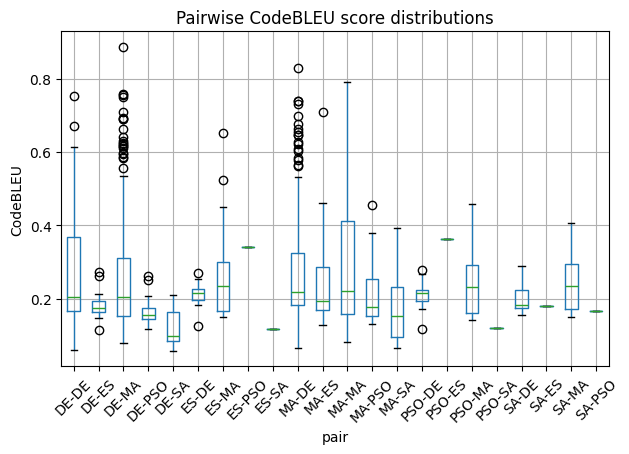

In [77]:
import pandas as pd
import numpy as np
from itertools import combinations, product
import matplotlib.pyplot as plt

pair_scores = []

categories = sorted(algo_df["category"].dropna().unique())

for cat_a in categories:
    for cat_b in categories:
        codes_a = algo_df.loc[algo_df["category"] == cat_a, "code"].tolist()
        codes_b = algo_df.loc[algo_df["category"] == cat_b, "code"].tolist()

        if cat_a == cat_b:
            pairs = combinations(codes_a, 2)
        else:
            pairs = product(codes_a, codes_b)

        for code_a, code_b in pairs:
            score = compute_codebleu_pair(code_a, code_b)
            if not np.isnan(score):
                pair_scores.append({
                    "pair": f"{cat_a}-{cat_b}",
                    "cat_a": cat_a,
                    "cat_b": cat_b,
                    "score": score
                })

pair_scores_df = pd.DataFrame(pair_scores)

plt.figure(figsize=(12, 5))
pair_scores_df.boxplot(column="score", by="pair", rot=45)
plt.title("Pairwise CodeBLEU score distributions")
plt.suptitle("")
plt.ylabel("CodeBLEU")
plt.tight_layout()
plt.show()

In [19]:
# ── Clean first ───────────────────────────────────────────────────────────
import numpy as np

FAILURE_SENTINEL = -1e6

print(f"Rows before cleaning: {len(df_plot)}")
bad_fitness = (
    (df_plot["fitness"] <= FAILURE_SENTINEL) |
    (df_plot["fitness"] == -np.inf) |
    df_plot["fitness"].isna()
)
print(f"Rows removed (failed fitness): {bad_fitness.sum()}")
df_clean = df_plot[~bad_fitness].reset_index(drop=True)
print(f"Rows after cleaning: {len(df_clean)}\n")

# ── Build algo_df: one row per unique (name, code) version ───────────────
algo_df = (
    df_clean[df_clean["code"].notna() & df_clean["algorithm_category"].notna()]
    .groupby(["name", "code"], sort=False)
    .agg(
        description=("description", "first") if "description" in df_clean.columns else ("code", "first"),
        category=("algorithm_category", "first"),
        best_fitness=("fitness", "max"),
        mean_fitness=("fitness", "mean"),
        n_runs=("fitness", "count"),        # how many times this version was evaluated
    )
    .reset_index()
)

# Add a unique version id for readability
algo_df["version_id"] = (
    algo_df["name"] + "_v" +
    algo_df.groupby("name").cumcount().add(1).astype(str)
)

# Secondary guard
failed_mask = algo_df["best_fitness"] <= FAILURE_SENTINEL
print(f"Versions excluded after cleaning: {failed_mask.sum()}")
algo_df = algo_df[~failed_mask].reset_index(drop=True)

print(f"Unique algorithm versions for CodeBLEU: {len(algo_df)}")
print(f"Unique algorithm names: {algo_df['name'].nunique()}")
print(algo_df["category"].value_counts())

# ── Lookups keyed by version_id ───────────────────────────────────────────
fitness_lookup  = algo_df.set_index("version_id")["best_fitness"].to_dict()
category_lookup = algo_df.set_index("version_id")["category"].to_dict()
name_lookup     = algo_df.set_index("version_id")["name"].to_dict()
names_all       = algo_df["version_id"].tolist()
codes_all       = algo_df["code"].tolist()

def safe_fitness(version_id):
    v = fitness_lookup.get(version_id, np.nan)
    if v is None or v <= FAILURE_SENTINEL:
        return np.nan
    return float(v)

# Verify
bad_in_lookup = {k: v for k, v in fitness_lookup.items() if v <= FAILURE_SENTINEL}
print(f"\nSentinel values still in fitness_lookup: {len(bad_in_lookup)}")

Rows before cleaning: 976
Rows removed (failed fitness): 189
Rows after cleaning: 787

Versions excluded after cleaning: 0
Unique algorithm versions for CodeBLEU: 398
Unique algorithm names: 34
category
DE     151
MA     130
PSO     89
ES      28
Name: count, dtype: int64

Sentinel values still in fitness_lookup: 0


Rows before cleaning: 3959
Rows removed (failed fitness): 640
Categories with >= 50 runs: ['DE', 'ES', 'MA', 'PSO']
Dropped categories: ['SA']

Total unique (name, code) versions: 1610
category
MA     550
DE     486
PSO    318
ES     256
Name: count, dtype: int64

Strategy A (best+worst+median): 208 versions
category
DE     89
MA     61
ES     30
PSO    28
Name: count, dtype: int64

Strategy B (stratified across fitness bins): 299 versions
category
DE     121
MA      91
ES      46
PSO     41
Name: count, dtype: int64

Final algo_df after combining strategies: 356 versions
category
DE     147
MA     103
ES      54
PSO     52
Name: count, dtype: int64

Unique algorithms for CodeBLEU: 356
category
DE     147
MA     103
ES      54
PSO     52
Name: count, dtype: int64

Sentinel values still in fitness_lookup: 0


CodeBLEU: 100%|██████████| 63190/63190 [1:53:21<00:00,  9.29it/s]



Total scored pairs: 63190
Expected unordered pairs: 63190
Pairs with NaN fitness_diff: 0
fitness_diff range: 0.000000 → 0.258156

Category-pair CodeBLEU matrix:
           DE        ES        MA       PSO
DE   0.295609  0.287670  0.258457  0.237600
ES   0.287670  0.327679  0.275311  0.251602
MA   0.258457  0.275311  0.268341  0.222006
PSO  0.237600  0.251602  0.222006  0.270110


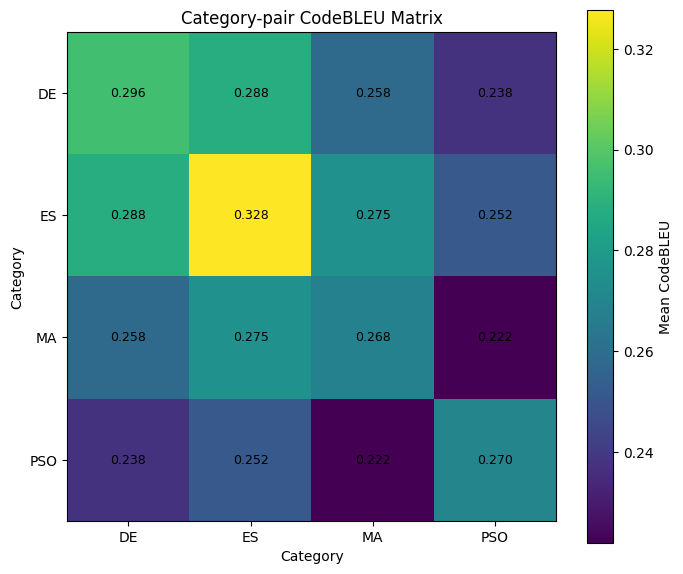

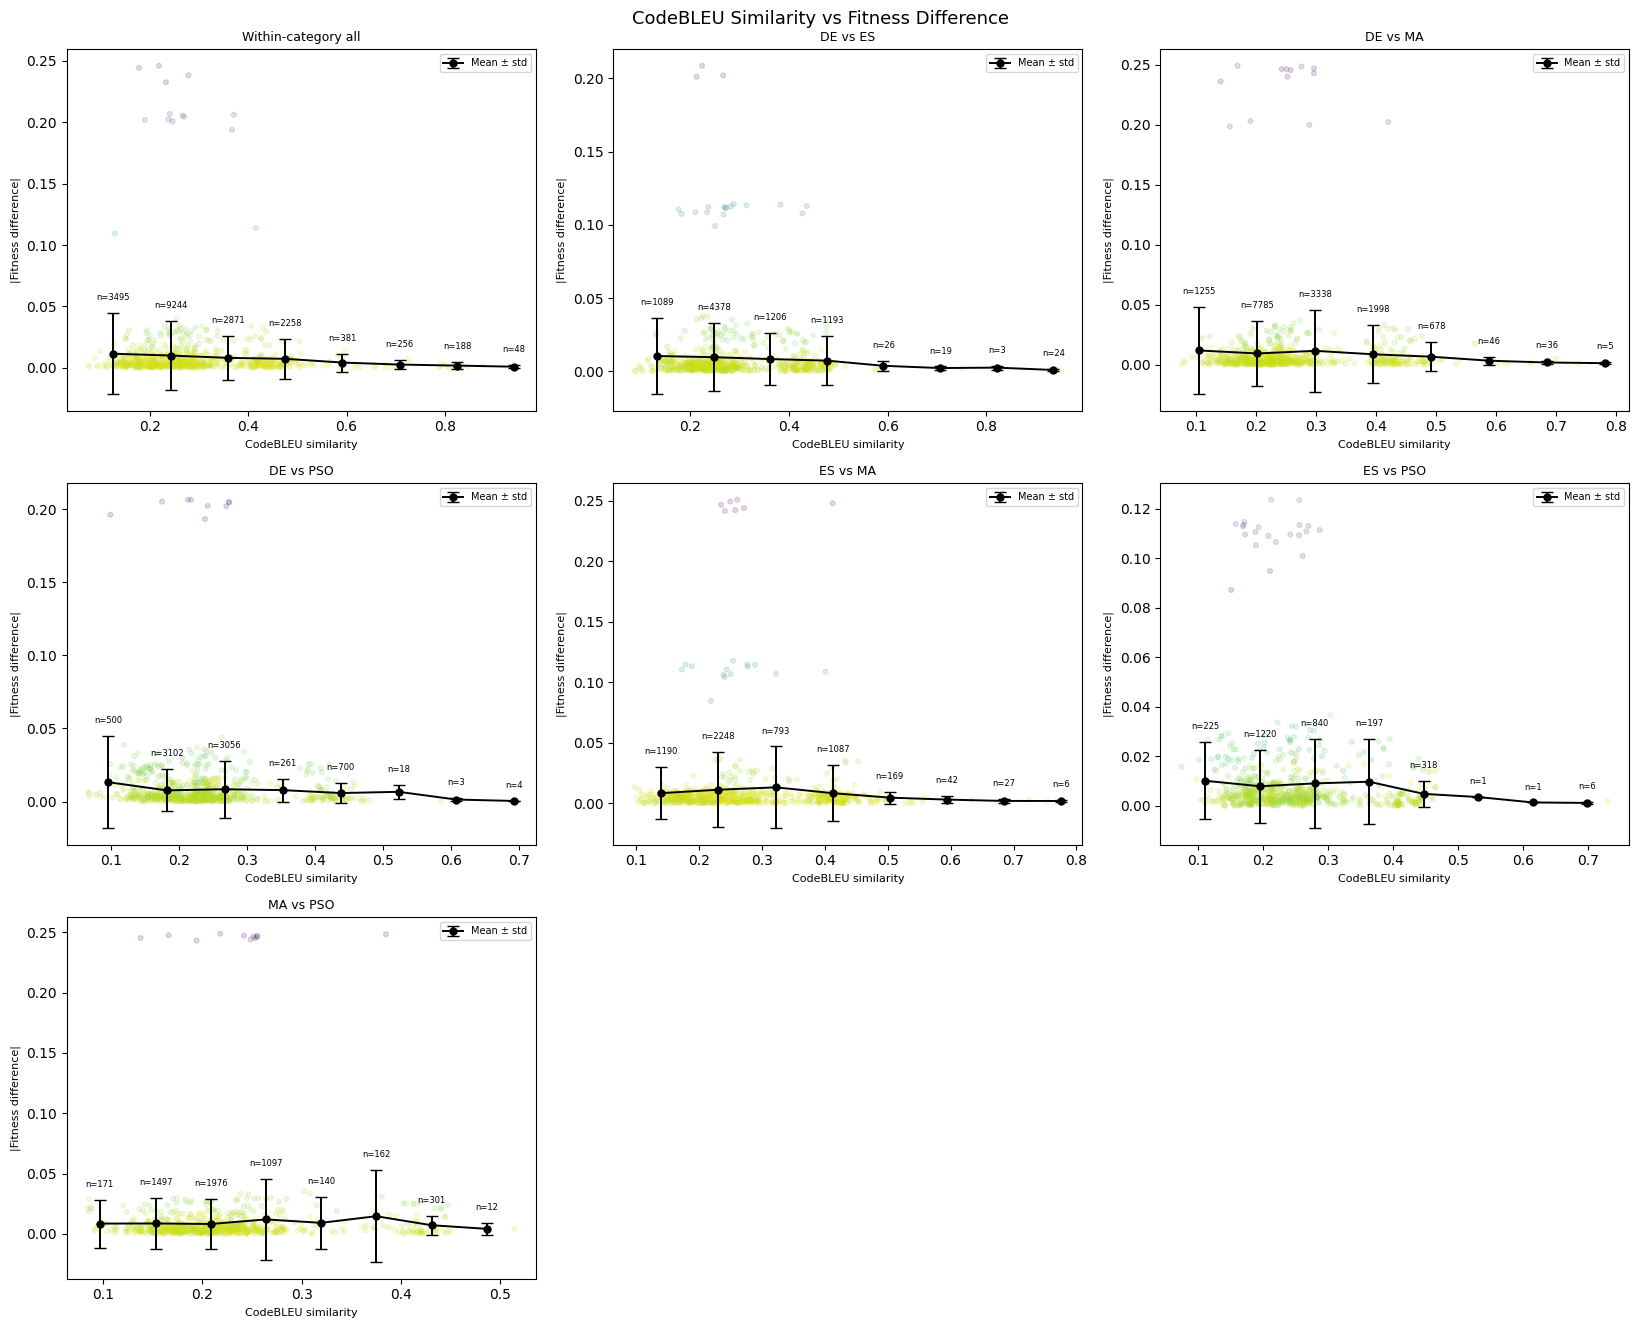


── Binned CodeBLEU vs fitness_diff summary ──

Within-category all:
                     mean       std  count
codebleu_bin                              
(0.0643, 0.183]  0.011444  0.033069   3495
(0.183, 0.3]     0.009956  0.027893   9244
(0.3, 0.416]     0.008070  0.017672   2871
(0.416, 0.533]   0.007297  0.016269   2258
(0.533, 0.65]    0.004227  0.007384    381
(0.65, 0.767]    0.002601  0.003769    256
(0.767, 0.883]   0.001762  0.002825    188
(0.883, 1.0]     0.000854  0.001138     48

DE vs ES:
                    mean       std  count
codebleu_bin                             
(0.0739, 0.19]  0.010423  0.026158   1089
(0.19, 0.305]   0.009592  0.023392   4378
(0.305, 0.42]   0.008325  0.017733   1206
(0.42, 0.534]   0.007255  0.016604   1193
(0.534, 0.649]  0.003731  0.003297     26
(0.649, 0.764]  0.002177  0.001170     19
(0.764, 0.878]  0.002483  0.001384      3
(0.878, 0.993]  0.000874  0.000502     24

DE vs MA:
                     mean       std  count
codebleu_bin    

c:\Users\Anna Michelle\.conda\envs\codebleu311\Lib\site-packages\sklearn\manifold\_mds.py:735: FutureWarning: The default value of `init` will change from 'random' to 'classical_mds' in 1.10. To suppress this warning, provide some value of `init`.
  warnings.warn(
c:\Users\Anna Michelle\.conda\envs\codebleu311\Lib\site-packages\sklearn\manifold\_mds.py:752: FutureWarning: The `dissimilarity` parameter is deprecated and will be removed in 1.10. Use `metric` instead.
  warnings.warn(


MDS stress: 4757.9060
MDS normalized stress: 0.3701


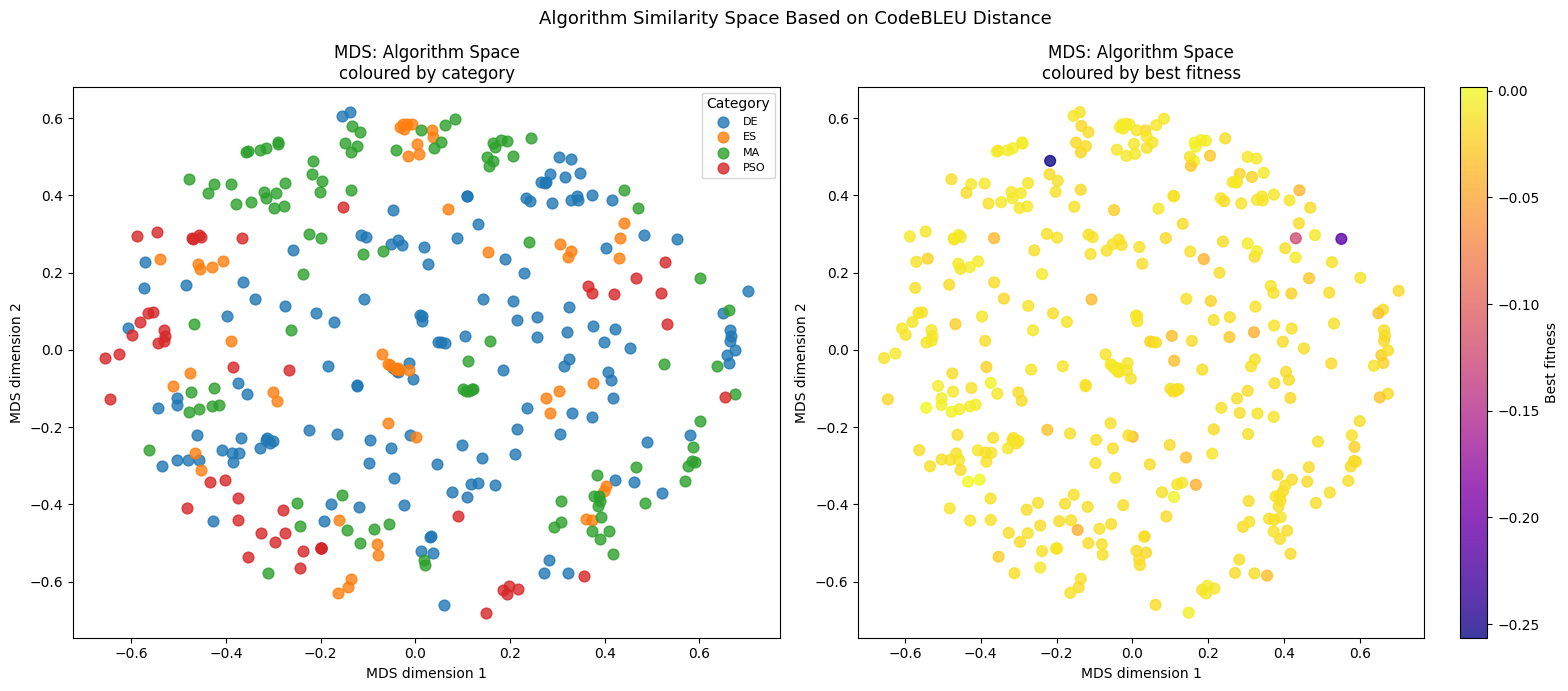

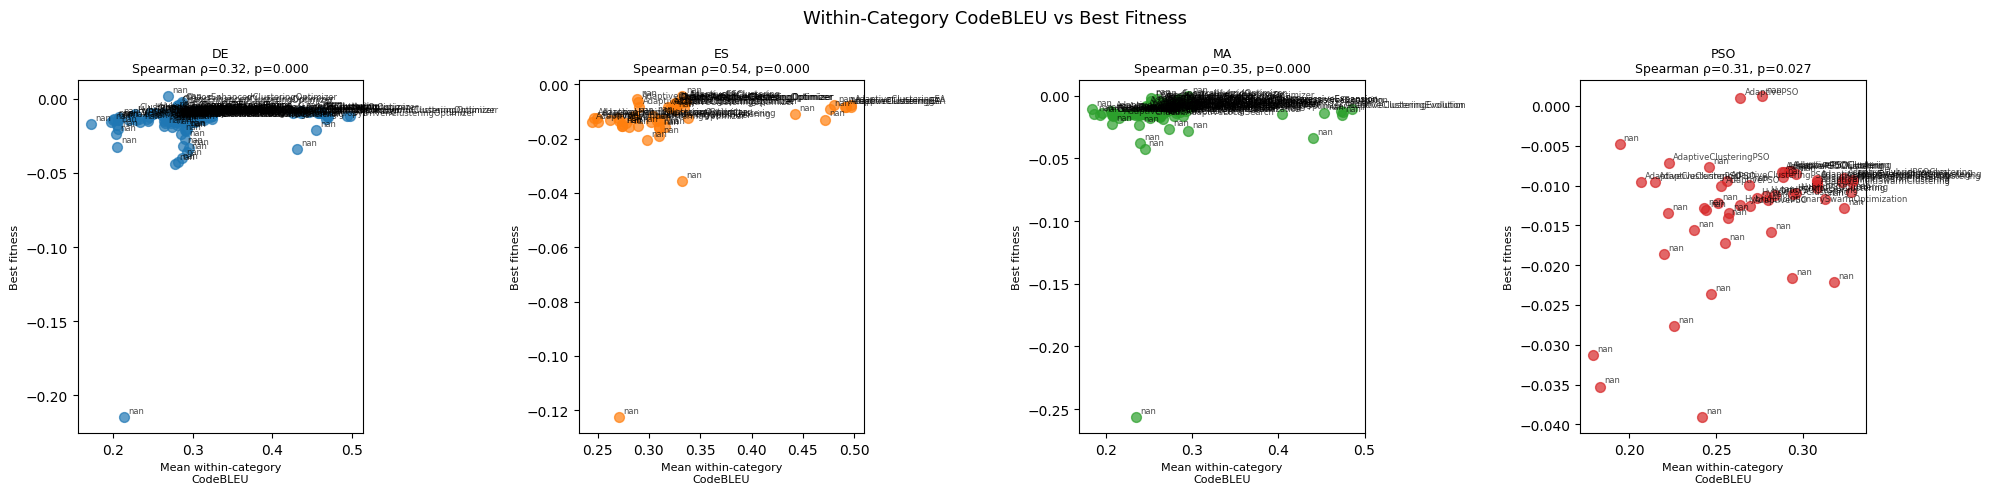

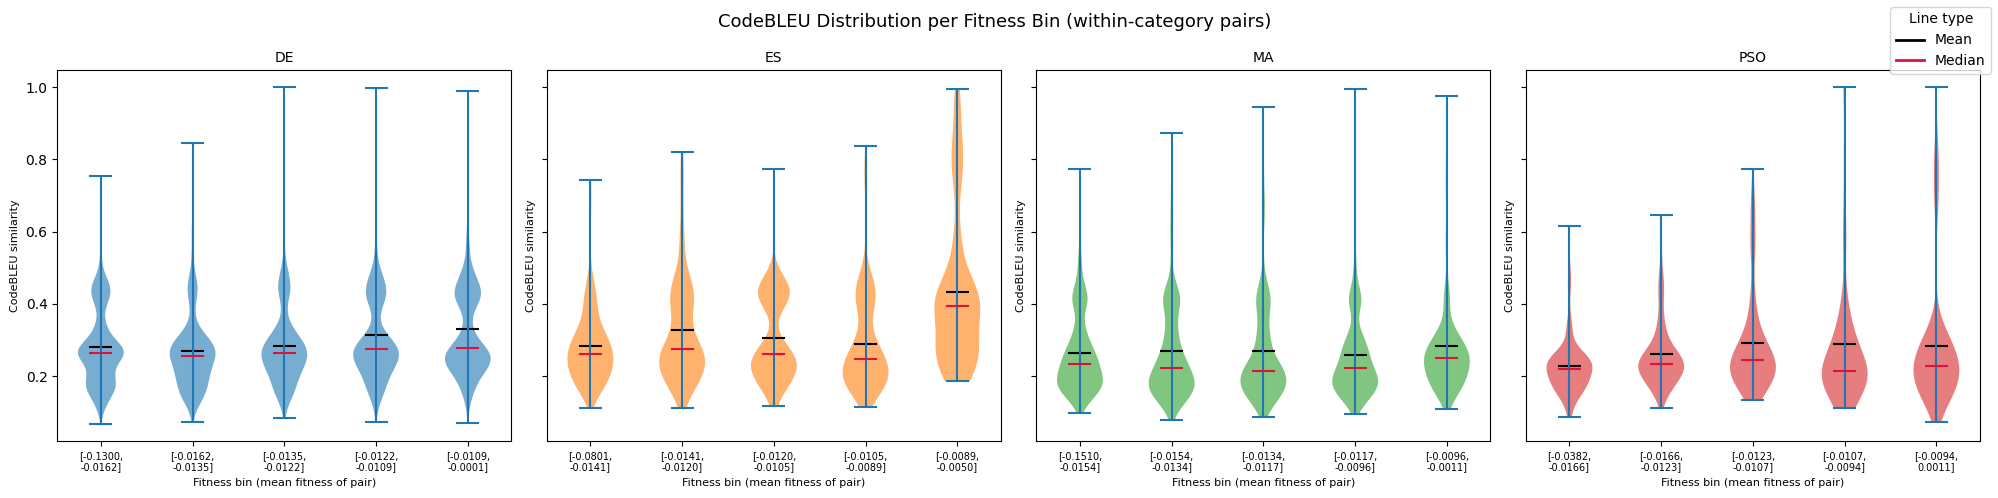


── Mean CodeBLEU per fitness bin ──

DE:
                      mean_codebleu  std_codebleu  n_pairs
fitness_bin                                               
(-0.13, -0.0162]           0.279754      0.106377     2147
(-0.0162, -0.0135]         0.270443      0.111980     2146
(-0.0135, -0.0122]         0.284349      0.112106     2146
(-0.0122, -0.0109]         0.314619      0.138120     2146
(-0.0109, -9.67e-05]       0.328885      0.136812     2146

ES:
                      mean_codebleu  std_codebleu  n_pairs
fitness_bin                                               
(-0.0801, -0.0141]         0.284330      0.108395      287
(-0.0141, -0.012]          0.327352      0.144706      286
(-0.012, -0.0105]          0.305509      0.119772      286
(-0.0105, -0.00888]        0.289240      0.131351      286
(-0.00888, -0.00497]       0.432116      0.210057      286

MA:
                      mean_codebleu  std_codebleu  n_pairs
fitness_bin                                               
(-0.

,name,category,best_fitness,mean_fitness,mean_codebleu_within
104,NaN,DE,0.001739,-0.004816,0.269154
132,NaN,DE,-0.001933,-0.012195,0.287148
233,ChaosEnhancedClusteringOptimizer,DE,-0.003187,-0.004944,0.285921
234,ChaosEnhancedClusteringOptimizer,DE,-0.004301,-0.008222,0.281864
235,ChaosEnhancedClusteringOptimizer,DE,-0.005031,-0.008099,0.280908
...,...,...,...,...,...
30,NaN,PSO,-0.023662,-0.023662,0.247215
93,NaN,PSO,-0.027635,-0.027635,0.225874
96,NaN,PSO,-0.031270,-0.031270,0.179250
97,NaN,PSO,-0.035247,-0.035247,0.183339


,pair,cat_a,cat_b,version_id_a,version_id_b,name_a,name_b,codebleu,fitness_a,fitness_b,fitness_diff,fitness_mean,is_within
0,DE-MA,MA,DE,AdaptiveChaosClusteringOptimizer_v1,AdaptiveChaosDEOptimizer_v8,NaN,NaN,0.186151,-0.015524,-0.010410,0.005114,-0.012967,False
1,DE-MA,MA,DE,AdaptiveChaosClusteringOptimizer_v1,AdaptiveChaosDEOptimizer_v10,NaN,NaN,0.183390,-0.015524,-0.023342,0.007818,-0.019433,False
2,DE-MA,MA,DE,AdaptiveChaosClusteringOptimizer_v1,AdaptiveChaosDEOptimizer_v5,NaN,NaN,0.192806,-0.015524,-0.012952,0.002573,-0.014238,False
3,DE-MA,MA,DE,AdaptiveChaosClusteringOptimizer_v1,AdaptiveChaosHybridDE_v1,NaN,NaN,0.446388,-0.015524,-0.016840,0.001316,-0.016182,False
4,DE-MA,MA,DE,AdaptiveChaosClusteringOptimizer_v1,AdaptiveChaoticClusteringOptimizer_v13,NaN,NaN,0.174756,-0.015524,-0.010064,0.005460,-0.012794,False


In [5]:
import math
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.cm as cm

from tqdm import tqdm
from itertools import combinations
from scipy.stats import spearmanr
from sklearn.manifold import MDS
from codebleu import calc_codebleu


# ════════════════════════════════════════════════════════════════════════════
# CONFIG
# ════════════════════════════════════════════════════════════════════════════

FAILURE_THRESHOLD = -1e6

# Use "max" if higher fitness is better.
# Use "min" if your fitness is MSE or another error metric where lower is better.
FITNESS_MODE = "max"   # change to "min" for MSE


# ════════════════════════════════════════════════════════════════════════════
# CODEBLEU HELPER
# ════════════════════════════════════════════════════════════════════════════

def compute_codebleu_pair(reference_code, prediction_code):
    reference_code = "" if reference_code is None else str(reference_code)
    prediction_code = "" if prediction_code is None else str(prediction_code)

    if not reference_code.strip() or not prediction_code.strip():
        return np.nan

    try:
        result = calc_codebleu(
            references=[reference_code],
            predictions=[prediction_code],
            lang="python",
            # Data-flow ignored because CodeBLEU warnings showed it was unreliable
            weights=(1/3, 1/3, 0.0, 1/3),
        )

        score = result.get("codebleu", result.get("CodeBLEU"))
        return float(score) if score is not None else np.nan

    except Exception as e:
        print("CodeBLEU failed for one pair:", type(e).__name__, e)
        return np.nan


def safe_spearman(x, y):
    """Compute Spearman only when there is enough non-constant data."""
    if len(x) < 4:
        return np.nan, np.nan
    if pd.Series(x).nunique() <= 1 or pd.Series(y).nunique() <= 1:
        return np.nan, np.nan
    return spearmanr(x, y)


# ════════════════════════════════════════════════════════════════════════════
# CLEAN DATA
# ════════════════════════════════════════════════════════════════════════════

print(f"Rows before cleaning: {len(df_plot)}")

bad_fitness = (
    (df_plot["fitness"] < FAILURE_THRESHOLD) |
    (df_plot["fitness"] == -np.inf) |
    (df_plot["fitness"] == np.inf) |
    (df_plot["fitness"].isna())
)

print(f"Rows removed (failed fitness): {bad_fitness.sum()}")

df_clean = df_plot[~bad_fitness].copy().reset_index(drop=True)

df_clean["code"] = df_clean["code"].fillna("").astype(str)
df_clean = df_clean[
    df_clean["code"].str.strip().ne("") &
    df_clean["algorithm_category"].notna() &
    df_clean["name"].notna()
].reset_index(drop=True)

MIN_RUNS = 50
N_FITNESS_BINS = 5  # for stratified sampling

# ── Step 1: drop algorithm names with fewer than 50 runs ─────────────────
run_counts = df_clean.groupby("algorithm_category").size()
valid_categories = run_counts[run_counts >= MIN_RUNS].index
print(f"Categories with >= {MIN_RUNS} runs: {sorted(valid_categories.tolist())}")
print(f"Dropped categories: {sorted(run_counts[run_counts < MIN_RUNS].index.tolist())}")
df_clean = df_clean[df_clean["algorithm_category"].isin(valid_categories)].reset_index(drop=True)

# ── Step 2: per (name, code) version — aggregate fitness ─────────────────
agg_dict = {
    "category":     ("algorithm_category", "first"),  # maps algorithm_category → category
    "best_fitness": ("fitness", "max" if FITNESS_MODE == "max" else "min"),
    "mean_fitness": ("fitness", "mean"),
    "n_runs":       ("fitness", "count"),
}

if "description" in df_clean.columns:
    agg_dict["description"] = ("description", "first")

version_df = (
    df_clean
    .groupby(["name", "code"], as_index=False)
    .agg(**agg_dict)
)

version_df["version_id"] = (
    version_df["name"] + "_v" +
    version_df.groupby("name").cumcount().add(1).astype(str)
)

print(f"\nTotal unique (name, code) versions: {len(version_df)}")
print(version_df["category"].value_counts())

# ── Step 3: select representative versions per algorithm name ─────────────
# Strategy A: best + worst + median (3 versions per name)
# Strategy B: stratified sample across fitness bins per category

def select_best_worst_median(grp):
    if len(grp) == 1:
        return grp
    if len(grp) == 2:
        return grp
    sorted_grp = grp.sort_values("best_fitness", ascending=False)
    best   = sorted_grp.iloc[[0]]
    worst  = sorted_grp.iloc[[-1]]
    median = sorted_grp.iloc[[len(sorted_grp) // 2]]
    return pd.concat([best, worst, median]).drop_duplicates(subset="version_id")

strategy_a = (
    version_df
    .groupby("name", group_keys=False)
    .apply(select_best_worst_median)
    .reset_index(drop=True)
)
print(f"\nStrategy A (best+worst+median): {len(strategy_a)} versions")
print(strategy_a["category"].value_counts())

def stratified_fitness_sample(grp, n_bins=N_FITNESS_BINS):
    if len(grp) <= n_bins:
        return grp
    try:
        grp = grp.copy()
        grp["_bin"] = pd.qcut(grp["best_fitness"], q=n_bins, duplicates="drop", labels=False)
        return (
            grp.groupby("_bin", group_keys=False)
            .apply(lambda b: b.nlargest(1, "best_fitness"))
            .drop(columns="_bin")
            .reset_index(drop=True)
        )
    except Exception:
        return grp.nlargest(n_bins, "best_fitness")

strategy_b = (
    version_df
    .groupby(["category", "name"], group_keys=False)
    .apply(stratified_fitness_sample)
    .reset_index(drop=True)
)

for col in ["name", "category"]:
    if col not in strategy_b.columns:
        strategy_b = strategy_b.merge(
            version_df[["version_id", col]],
            on="version_id",
            how="left"
        )

print(f"\nStrategy B (stratified across fitness bins): {len(strategy_b)} versions")
print(strategy_b["category"].value_counts())

# ── Step 4: merge both strategies, deduplicate ────────────────────────────
algo_df = (
    pd.concat([strategy_a, strategy_b])
    .drop_duplicates(subset="version_id")
    .reset_index(drop=True)
)

print(f"\nFinal algo_df after combining strategies: {len(algo_df)} versions")
print(algo_df["category"].value_counts())

# ── Lookups ───────────────────────────────────────────────────────────────
fitness_lookup  = algo_df.set_index("version_id")["best_fitness"].to_dict()
category_lookup = algo_df.set_index("version_id")["category"].to_dict()
name_lookup     = algo_df.set_index("version_id")["name"].to_dict()
names_all       = algo_df["version_id"].tolist()
categories      = sorted(algo_df["category"].dropna().unique())

def safe_fitness(version_id):
    v = fitness_lookup.get(version_id, np.nan)
    if v is None or pd.isna(v) or v < FAILURE_THRESHOLD:
        return np.nan
    return float(v)

print(f"\nUnique algorithms for CodeBLEU: {len(algo_df)}")
print(algo_df["category"].value_counts())


bad_in_lookup = {k: v for k, v in fitness_lookup.items() if v < FAILURE_THRESHOLD}
print(f"\nSentinel values still in fitness_lookup: {len(bad_in_lookup)}")
for k, v in bad_in_lookup.items():
    print(f"  {k}: {v}")


# ════════════════════════════════════════════════════════════════════════════
# PAIRWISE CODEBLEU
# ════════════════════════════════════════════════════════════════════════════

pair_scores_named = []

algo_records = algo_df[["version_id", "name", "code", "category"]].to_dict("records")
total_pairs = len(algo_records) * (len(algo_records) - 1) // 2

for a, b in tqdm(combinations(algo_records, 2), total=total_pairs, desc="CodeBLEU"):
    name_a, code_a, cat_a, vid_a = a["name"], a["code"], a["category"], a["version_id"]
    name_b, code_b, cat_b, vid_b = b["name"], b["code"], b["category"], b["version_id"]

    score = compute_codebleu_pair(code_a, code_b)

    if not np.isnan(score):
        fa = safe_fitness(vid_a)
        fb = safe_fitness(vid_b)

        pair_scores_named.append({
            "pair":         "-".join(sorted([cat_a, cat_b])),
            "cat_a":        cat_a,
            "cat_b":        cat_b,
            "version_id_a": vid_a,
            "version_id_b": vid_b,
            "name_a":       name_a,
            "name_b":       name_b,
            "codebleu":     score,
            "fitness_a":    fa,
            "fitness_b":    fb,
            "fitness_diff": abs(fa - fb) if not (np.isnan(fa) or np.isnan(fb)) else np.nan,
            "fitness_mean": np.nanmean([fa, fb]) if not (np.isnan(fa) and np.isnan(fb)) else np.nan,
            "is_within":    cat_a == cat_b,
        })

psn = pd.DataFrame(pair_scores_named)

print(f"\nTotal scored pairs: {len(psn)}")
print(f"Expected unordered pairs: {total_pairs}")

if not psn.empty:
    print(f"Pairs with NaN fitness_diff: {psn['fitness_diff'].isna().sum()}")
    print(f"fitness_diff range: {psn['fitness_diff'].min():.6f} → {psn['fitness_diff'].max():.6f}")


# ════════════════════════════════════════════════════════════════════════════
# CATEGORY-PAIR CODEBLEU MATRIX
# ════════════════════════════════════════════════════════════════════════════

matrix = pd.DataFrame(index=categories, columns=categories, dtype=float)

for cat_a in categories:
    for cat_b in categories:
        if cat_a == cat_b:
            sub = psn[
                (psn["cat_a"] == cat_a) &
                (psn["cat_b"] == cat_b)
            ]
        else:
            sub = psn[
                ((psn["cat_a"] == cat_a) & (psn["cat_b"] == cat_b)) |
                ((psn["cat_a"] == cat_b) & (psn["cat_b"] == cat_a))
            ]

        matrix.loc[cat_a, cat_b] = sub["codebleu"].mean()

print("\nCategory-pair CodeBLEU matrix:")
print(matrix)


plt.figure(figsize=(7, 6))
plt.imshow(matrix.astype(float), interpolation="nearest")
plt.colorbar(label="Mean CodeBLEU")
plt.xticks(range(len(categories)), categories)
plt.yticks(range(len(categories)), categories)

for i, cat_a in enumerate(categories):
    for j, cat_b in enumerate(categories):
        value = matrix.loc[cat_a, cat_b]
        if not pd.isna(value):
            plt.text(j, i, f"{value:.3f}", ha="center", va="center", fontsize=9)

plt.title("Category-pair CodeBLEU Matrix")
plt.xlabel("Category")
plt.ylabel("Category")
plt.tight_layout()
plt.show()


# ════════════════════════════════════════════════════════════════════════════
# ANALYSIS 1: CODEBLEU SIMILARITY VS FITNESS DIFFERENCE
# ════════════════════════════════════════════════════════════════════════════

within = psn[psn["is_within"]]

between_pairs = [
    (a, b)
    for i, a in enumerate(categories)
    for b in categories[i + 1:]
]

plot_groups = [("Within-category all", within)] + [
    (
        f"{a} vs {b}",
        psn[
            ((psn["cat_a"] == a) & (psn["cat_b"] == b)) |
            ((psn["cat_a"] == b) & (psn["cat_b"] == a))
        ]
    )
    for a, b in between_pairs
]

# ════════════════════════════════════════════════════════════════════════════
# ANALYSIS 1: CODEBLEU BINS VS FITNESS DIFFERENCE (mean ± std)
# ════════════════════════════════════════════════════════════════════════════

N_CODEBLEU_BINS = 8
MAX_PAIRS_PER_PANEL = 800  # raw points shown underneath summary

n_plots = len(plot_groups)
ncols = 3
nrows = math.ceil(n_plots / ncols)

fig, axes = plt.subplots(nrows, ncols, figsize=(5.5 * ncols, 4.5 * nrows))
axes = np.array(axes).flatten()

for ax, (label, sub) in zip(axes, plot_groups):
    sub = sub.dropna(subset=["fitness_diff", "codebleu", "fitness_mean"])

    if sub.empty:
        ax.set_visible(False)
        continue

    # ── Bin CodeBLEU axis ────────────────────────────────────────────────
    try:
        sub = sub.copy()
        sub["codebleu_bin"] = pd.cut(
            sub["codebleu"],
            bins=N_CODEBLEU_BINS,
            include_lowest=True
        )

        binned = (
            sub.groupby("codebleu_bin", observed=True)["fitness_diff"]
            .agg(["mean", "std", "count"])
            .reset_index()
        )
        binned["bin_mid"] = binned["codebleu_bin"].apply(lambda b: b.mid)
        binned["std"] = binned["std"].fillna(0)

        # ── Raw points (sampled) ─────────────────────────────────────────
        sample = sub.sample(min(MAX_PAIRS_PER_PANEL, len(sub)), random_state=42)
        ax.scatter(
            sample["codebleu"],
            sample["fitness_diff"],
            alpha=0.15,
            s=12,
            c=sample["fitness_mean"],
            cmap="viridis",
            zorder=1
        )

        # ── Mean ± std per bin ───────────────────────────────────────────
        ax.errorbar(
            binned["bin_mid"],
            binned["mean"],
            yerr=binned["std"],
            fmt="o-",
            color="black",
            linewidth=1.4,
            markersize=5,
            capsize=4,
            zorder=3,
            label="Mean ± std"
        )
        y_min, y_max = ax.get_ylim()
        y_offset = 0.03 * (y_max - y_min)  # increase to 0.05 if needed

        # ── Annotate bin counts ──────────────────────────────────────────
        for _, row in binned.iterrows():
            ax.annotate(
                f"n={int(row['count'])}",
                (row["bin_mid"], row["mean"] + row["std"] + y_offset),
                fontsize=6,
                ha="center",
                va="bottom",
                color="black",
                zorder=4
            )

    except Exception as e:
        ax.set_title(f"{label}\nBinning error: {e}", fontsize=8)
        continue

    # ── Spearman on full unbinned data ───────────────────────────────────
    rho, pval = safe_spearman(sub["codebleu"], sub["fitness_diff"])

    if np.isnan(rho):
        ax.set_title(f"{label}\nNot enough variation", fontsize=9)
    else:
        ax.set_title(f"{label}", fontsize=9)

    ax.set_xlabel("CodeBLEU similarity", fontsize=8)
    ax.set_ylabel("|Fitness difference|", fontsize=8)
    ax.legend(fontsize=7)

for ax in axes[len(plot_groups):]:
    ax.set_visible(False)

plt.suptitle("CodeBLEU Similarity vs Fitness Difference", fontsize=13)
plt.tight_layout()
plt.show()

# ── Summary table ────────────────────────────────────────────────────────
print("\n── Binned CodeBLEU vs fitness_diff summary ──")
for label, sub in plot_groups:
    sub = sub.dropna(subset=["fitness_diff", "codebleu"])
    if sub.empty:
        continue
    try:
        sub = sub.copy()
        sub["codebleu_bin"] = pd.cut(sub["codebleu"], bins=N_CODEBLEU_BINS, include_lowest=True)
        binned = (
            sub.groupby("codebleu_bin", observed=True)["fitness_diff"]
            .agg(["mean", "std", "count"])
        )
        print(f"\n{label}:")
        print(binned.to_string())
    except Exception as e:
        print(f"{label}: Error — {e}")


# ════════════════════════════════════════════════════════════════════════════
# ANALYSIS 2: MDS ON CODEBLEU DISTANCE
# ════════════════════════════════════════════════════════════════════════════

n = len(names_all)
name_idx = {name: i for i, name in enumerate(names_all)}

assert n > 0, "names_all is empty — algo_df was not built correctly."

dist_matrix = np.ones((n, n), dtype=float)
np.fill_diagonal(dist_matrix, 0.0)

for _, row in psn.iterrows():
    i = name_idx.get(row["version_id_a"])
    j = name_idx.get(row["version_id_b"])

    if i is not None and j is not None:
        d = 1.0 - float(row["codebleu"])
        d = np.clip(d, 0.0, 1.0)

        dist_matrix[i, j] = d
        dist_matrix[j, i] = d

print(f"\nMDS distance matrix shape: {dist_matrix.shape}")

try:
    mds = MDS(
        n_components=2,
        dissimilarity="precomputed",
        random_state=42,
        normalized_stress="auto"
    )
except TypeError:
    mds = MDS(
        n_components=2,
        dissimilarity="precomputed",
        random_state=42,
        n_init=10
    )

coords = mds.fit_transform(dist_matrix)

print(f"MDS stress: {mds.stress_:.4f}")
try:
    print(f"MDS normalized stress: {mds.normalized_stress_:.4f}")
except AttributeError:
    # normalized_stress_ only available in sklearn >= 1.1
    print(f"MDS normalized stress: {(mds.stress_ / (0.5 * np.sum(dist_matrix ** 2))) ** 0.5:.4f}")

fitness_vals = np.array([safe_fitness(vid) for vid in names_all])
cat_vals = [category_lookup.get(vid, "Other") for vid in names_all]
unique_cats = sorted(set(cat_vals))
cat_colors = {cat: cm.tab10(i % 10) for i, cat in enumerate(unique_cats)}

fig, axes = plt.subplots(1, 2, figsize=(16, 7))

ax = axes[0]
for cat in unique_cats:
    idx = [i for i, c in enumerate(cat_vals) if c == cat]

    ax.scatter(
        coords[idx, 0],
        coords[idx, 1],
        label=cat,
        alpha=0.8,
        s=60,
        color=cat_colors[cat]
    )

ax.set_title("MDS: Algorithm Space\ncoloured by category")
ax.set_xlabel("MDS dimension 1")
ax.set_ylabel("MDS dimension 2")
ax.legend(title="Category", fontsize=8)

ax = axes[1]
valid = ~np.isnan(fitness_vals)

sc = ax.scatter(
    coords[valid, 0],
    coords[valid, 1],
    c=fitness_vals[valid],
    cmap="plasma",
    alpha=0.8,
    s=60
)

plt.colorbar(sc, ax=ax, label="Best fitness")
ax.set_title("MDS: Algorithm Space\ncoloured by best fitness")
ax.set_xlabel("MDS dimension 1")
ax.set_ylabel("MDS dimension 2")

plt.suptitle("Algorithm Similarity Space Based on CodeBLEU Distance", fontsize=13)
plt.tight_layout()
plt.show()


# ════════════════════════════════════════════════════════════════════════════
# ANALYSIS 3: WITHIN-CATEGORY CODEBLEU VS BEST FITNESS
# ════════════════════════════════════════════════════════════════════════════

def mean_within_codebleu_for_algorithm(row):
    vid  = row["version_id"]
    cat  = row["category"]

    vals = psn.loc[
        ((psn["version_id_a"] == vid) | (psn["version_id_b"] == vid)) &
        (psn["is_within"]) &
        (psn["cat_a"] == cat) & (psn["cat_b"] == cat),
        "codebleu"
    ].values

    return np.nanmean(vals) if len(vals) > 0 else np.nan


algo_df["mean_codebleu_within"] = algo_df.apply(
    mean_within_codebleu_for_algorithm,
    axis=1
)

ncols = len(categories)
fig, axes = plt.subplots(1, ncols, figsize=(5 * ncols, 5), sharey=False)

if ncols == 1:
    axes = [axes]

for ax, cat in zip(axes, categories):
    sub = algo_df[algo_df["category"] == cat].dropna(
        subset=["mean_codebleu_within", "best_fitness"]
    )

    if len(sub) < 3:
        ax.scatter(
            sub["mean_codebleu_within"],
            sub["best_fitness"],
            alpha=0.7,
            s=50,
            color=cat_colors.get(cat)
        )
        ax.set_title(f"{cat}\nToo few points")
        ax.set_xlabel("Mean within-category CodeBLEU", fontsize=8)
        ax.set_ylabel("Best fitness", fontsize=8)
        continue

    rho, pval = safe_spearman(sub["mean_codebleu_within"], sub["best_fitness"])

    ax.scatter(
        sub["mean_codebleu_within"],
        sub["best_fitness"],
        alpha=0.7,
        s=50,
        color=cat_colors.get(cat)
    )

    for _, row in sub.iterrows():
        ax.annotate(
            row["name"],
            (row["mean_codebleu_within"], row["best_fitness"]),
            fontsize=6,
            alpha=0.7,
            xytext=(3, 3),
            textcoords="offset points"
        )

    if np.isnan(rho):
        ax.set_title(f"{cat}\nNot enough variation", fontsize=9)
    else:
        ax.set_title(f"{cat}\nSpearman ρ={rho:.2f}, p={pval:.3f}", fontsize=9)

    ax.set_xlabel("Mean within-category\nCodeBLEU", fontsize=8)
    ax.set_ylabel("Best fitness", fontsize=8)

plt.suptitle("Within-Category CodeBLEU vs Best Fitness", fontsize=13)
plt.tight_layout()
plt.show()

# ════════════════════════════════════════════════════════════════════════════
# FITNESS BINS VS CODEBLEU DISTRIBUTION
# ════════════════════════════════════════════════════════════════════════════

N_BINS = 5

fig, axes = plt.subplots(1, len(categories), figsize=(5 * len(categories), 5), sharey=True)

if len(categories) == 1:
    axes = [axes]

for ax, cat in zip(axes, categories):
    # Get all within-category pairs for this category
    sub = psn[
        (psn["cat_a"] == cat) &
        (psn["cat_b"] == cat)
    ].dropna(subset=["fitness_mean", "codebleu"])

    if sub.empty:
        ax.set_title(f"{cat}\n(no data)")
        continue

    try:
        sub = sub.copy()
        sub["fitness_bin"] = pd.qcut(
            sub["fitness_mean"],
            q=N_BINS,
            duplicates="drop"
        )

        bin_labels = sub["fitness_bin"].cat.categories
        codebleu_per_bin = [
            sub.loc[sub["fitness_bin"] == b, "codebleu"].values
            for b in bin_labels
        ]
        label_strs = [
            f"[{b.left:.4f},\n{b.right:.4f}]"
            for b in bin_labels
        ]

        vp = ax.violinplot(
            codebleu_per_bin,
            positions=range(len(bin_labels)),
            showmeans=True,
            showmedians=True
        )

        for pc in vp["bodies"]:
            pc.set_facecolor(cat_colors.get(cat, "steelblue"))
            pc.set_alpha(0.6)
        vp["cmeans"].set_color("black")
        vp["cmedians"].set_color("crimson")

        ax.set_xticks(range(len(bin_labels)))
        ax.set_xticklabels(label_strs, fontsize=7)
        ax.set_title(f"{cat}", fontsize=10)
        ax.set_xlabel("Fitness bin (mean fitness of pair)", fontsize=8)
        ax.set_ylabel("CodeBLEU similarity", fontsize=8)

    except Exception as e:
        ax.set_title(f"{cat}\nError: {e}")

# Shared legend
mean_line   = plt.Line2D([], [], color="black",  linewidth=2, label="Mean")
median_line = plt.Line2D([], [], color="crimson", linewidth=2, label="Median")
fig.legend(handles=[mean_line, median_line], loc="upper right", title="Line type")

plt.suptitle("CodeBLEU Distribution per Fitness Bin (within-category pairs)", fontsize=13)
plt.tight_layout()
plt.show()

# Summary table: mean CodeBLEU per bin per category
print("\n── Mean CodeBLEU per fitness bin ──")
for cat in categories:
    sub = psn[
        (psn["cat_a"] == cat) &
        (psn["cat_b"] == cat)
    ].dropna(subset=["fitness_mean", "codebleu"])

    if sub.empty:
        continue

    try:
        sub = sub.copy()
        sub["fitness_bin"] = pd.qcut(sub["fitness_mean"], q=N_BINS, duplicates="drop")
        print(f"\n{cat}:")
        print(
            sub.groupby("fitness_bin", observed=True)["codebleu"]
            .agg(["mean", "std", "count"])
            .rename(columns={"mean": "mean_codebleu", "std": "std_codebleu", "count": "n_pairs"})
            .to_string()
        )
    except Exception as e:
        print(f"{cat}: Error — {e}")
# ════════════════════════════════════════════════════════════════════════════
# CORRELATION SUMMARY
# ════════════════════════════════════════════════════════════════════════════

print("\n── Correlation summary: mean within-category CodeBLEU vs best fitness ──")
print(f"{'Category':<8} {'N':>4} {'Spearman ρ':>12} {'p-value':>10}")

for cat in categories:
    sub = algo_df[algo_df["category"] == cat].dropna(
        subset=["mean_codebleu_within", "best_fitness"]
    )

    if len(sub) < 3:
        print(f"{cat:<8} {len(sub):>4} {'—':>12} {'—':>10}")
        continue

    rho, pval = safe_spearman(sub["mean_codebleu_within"], sub["best_fitness"])

    if np.isnan(rho):
        print(f"{cat:<8} {len(sub):>4} {'—':>12} {'—':>10}")
    else:
        print(f"{cat:<8} {len(sub):>4} {rho:>12.3f} {pval:>10.4f}")


# Optional: show final tables
display(algo_df[[
    "name",
    "category",
    "best_fitness",
    "mean_fitness",
    "mean_codebleu_within"
]].sort_values(["category", "best_fitness"], ascending=[True, FITNESS_MODE != "max"]))

display(psn.head())

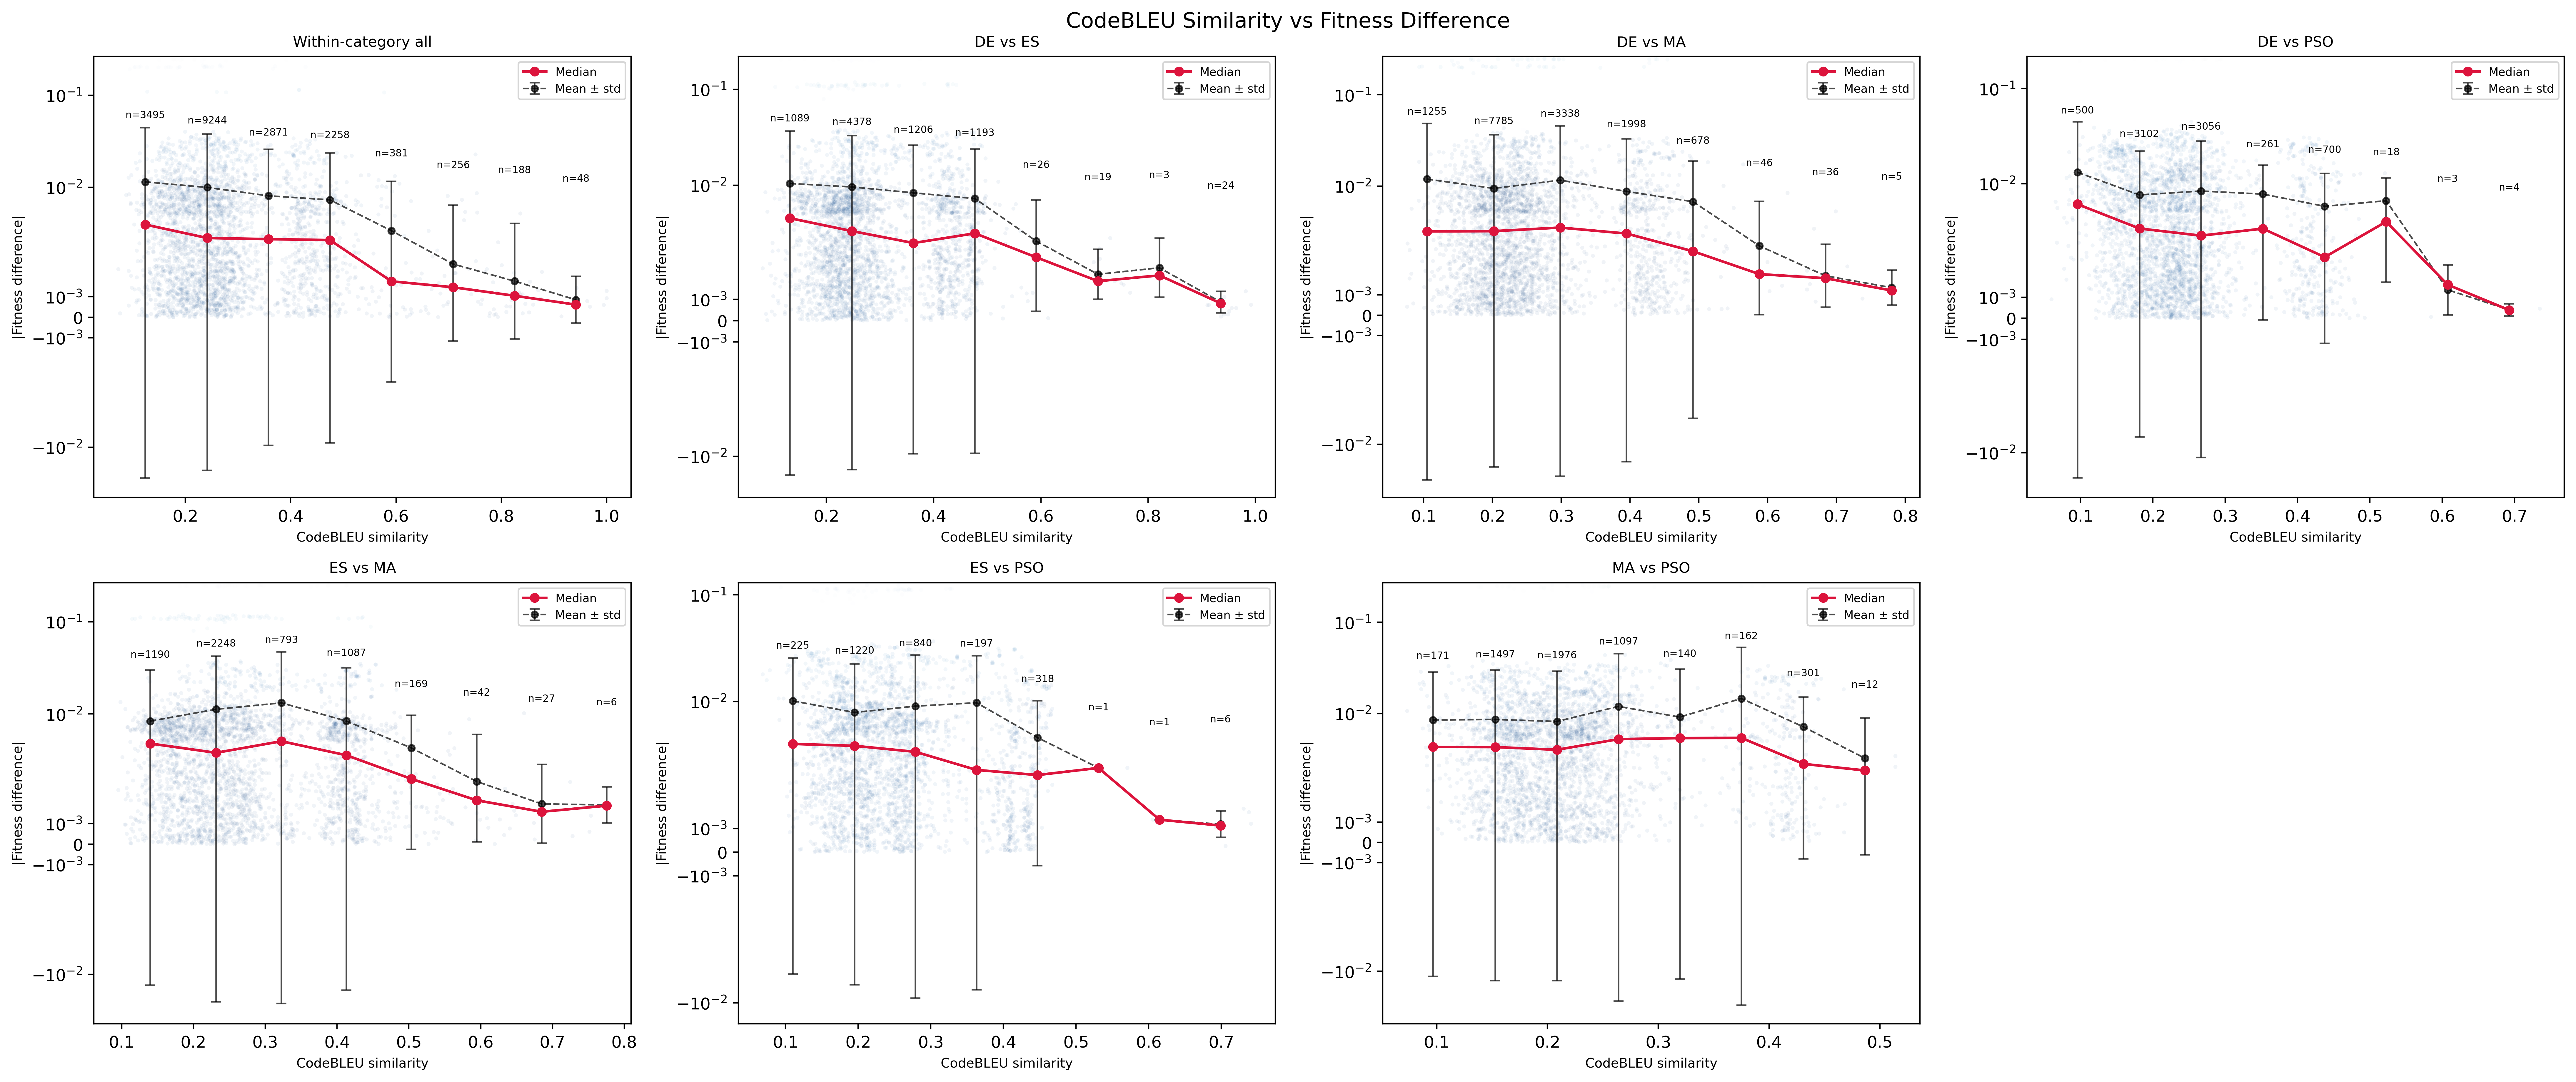

In [23]:
N_CODEBLEU_BINS = 8
MAX_PAIRS_PER_PANEL = 3000  # increase sample size since smaller points handle density better
Y_LINTHRESH = 0.005          # tune: below this, y-axis is linear; above, log

fig, axes = plt.subplots(nrows, ncols, figsize=(5.5 * ncols, 4.5 * nrows), dpi=400)
axes = np.array(axes).flatten()

for ax, (label, sub) in zip(axes, plot_groups):
    sub = sub.dropna(subset=["fitness_diff", "codebleu", "fitness_mean"])

    if sub.empty:
        ax.set_visible(False)
        continue

    try:
        sub = sub.copy()
        sub["codebleu_bin"] = pd.cut(
            sub["codebleu"],
            bins=N_CODEBLEU_BINS,
            include_lowest=True
        )

        binned = (
            sub.groupby("codebleu_bin", observed=True)["fitness_diff"]
            .agg(["mean", "median", "std", "count"])
            .reset_index()
        )
        binned["bin_mid"] = binned["codebleu_bin"].apply(lambda b: b.mid)
        binned["std"] = binned["std"].fillna(0)

        # ── Raw points: smaller, more transparent, more of them ────────────
        sample = sub.sample(min(MAX_PAIRS_PER_PANEL, len(sub)), random_state=42)
        ax.scatter(
            sample["codebleu"],
            sample["fitness_diff"],
            alpha=0.06,
            s=6,
            c=sample["fitness_mean"],
            cmap="Blues",
            edgecolors="none",
            zorder=1
        )

        # ── Median line (more robust than mean for skewed data) ────────────
        ax.plot(
            binned["bin_mid"],
            binned["median"],
            "o-",
            color="crimson",
            linewidth=1.6,
            markersize=5,
            zorder=3,
            label="Median"
        )

        # ── Mean ± std, kept as secondary reference ─────────────────────────
        ax.errorbar(
            binned["bin_mid"],
            binned["mean"],
            yerr=binned["std"],
            fmt="o--",
            color="black",
            linewidth=1.0,
            markersize=4,
            capsize=3,
            alpha=0.7,
            zorder=2,
            label="Mean ± std"
        )

        y_min, y_max = ax.get_ylim()
        y_offset = 0.03 * (y_max - y_min)

        for _, row in binned.iterrows():
            ax.annotate(
                f"n={int(row['count'])}",
                (row["bin_mid"], row["mean"] + row["std"] + y_offset),
                fontsize=6,
                ha="center",
                va="bottom",
                color="black",
                zorder=4
            )

    except Exception as e:
        ax.set_title(f"{label}\nBinning error: {e}", fontsize=8)
        continue

    rho, pval = safe_spearman(sub["codebleu"], sub["fitness_diff"])

    if np.isnan(rho):
        ax.set_title(f"{label}\nNot enough variation", fontsize=9)
    else:
        ax.set_title(f"{label}", fontsize=9)

    ax.set_yscale("symlog", linthresh=Y_LINTHRESH)
    ax.set_xlabel("CodeBLEU similarity", fontsize=8)
    ax.set_ylabel("|Fitness difference|", fontsize=8)
    ax.legend(fontsize=7)

for ax in axes[len(plot_groups):]:
    ax.set_visible(False)

plt.suptitle("CodeBLEU Similarity vs Fitness Difference", fontsize=13)
plt.tight_layout()
plt.show()

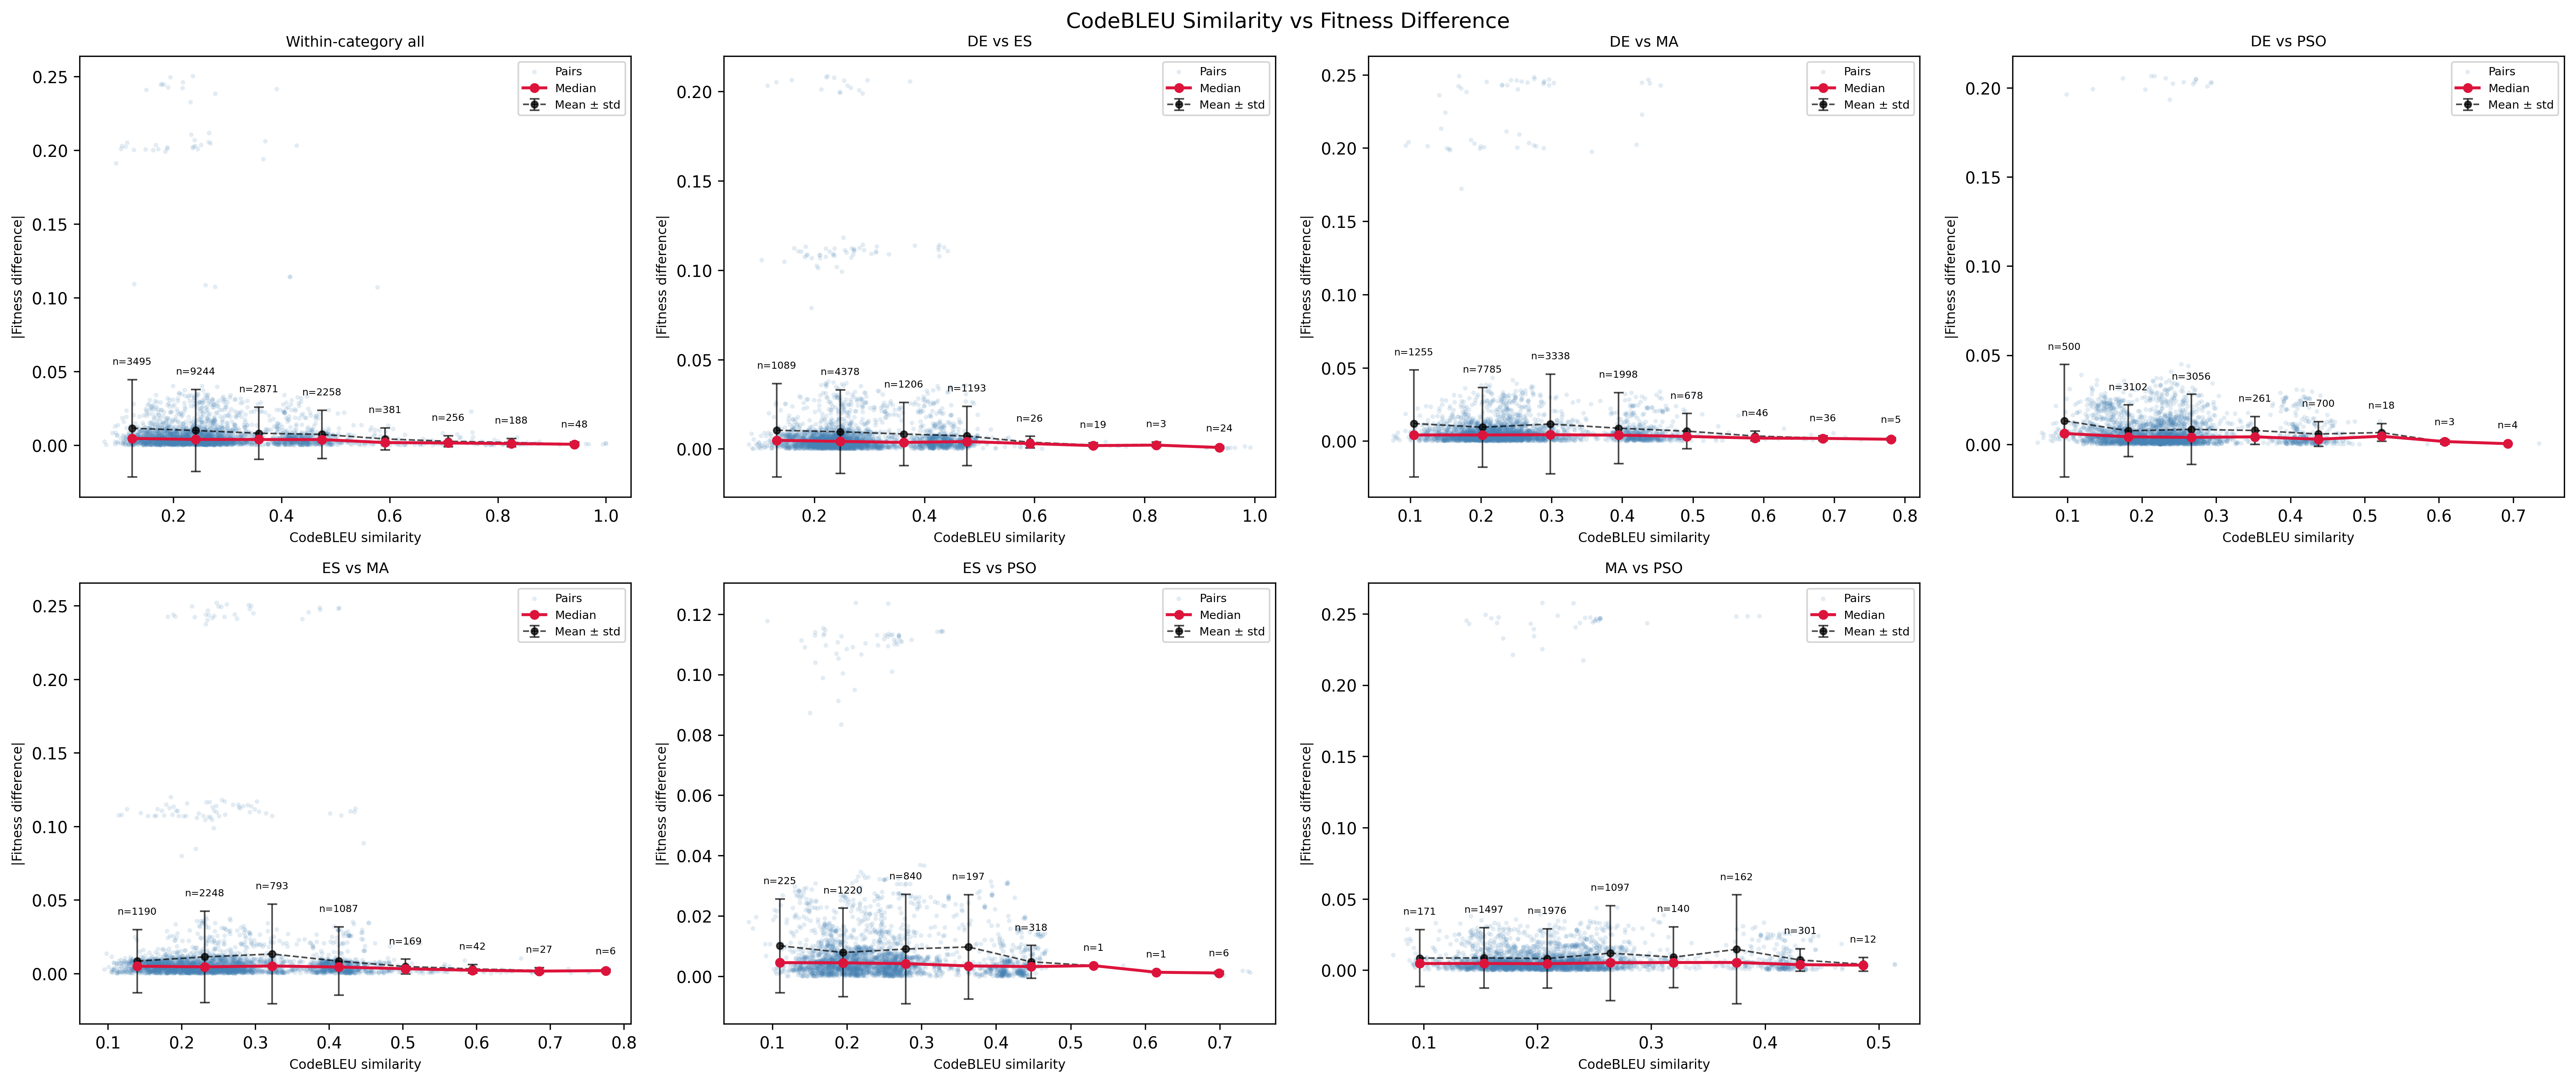

: 

In [ ]:
N_CODEBLEU_BINS = 8
MAX_PAIRS_PER_PANEL = 3000

fig, axes = plt.subplots(nrows, ncols, figsize=(5.5 * ncols, 4.5 * nrows), dpi = 300)
axes = np.array(axes).flatten()

for ax, (label, sub) in zip(axes, plot_groups):
    sub = sub.dropna(subset=["fitness_diff", "codebleu", "fitness_mean"])

    if sub.empty:
        ax.set_visible(False)
        continue

    try:
        sub = sub.copy()
        sub["codebleu_bin"] = pd.cut(
            sub["codebleu"],
            bins=N_CODEBLEU_BINS,
            include_lowest=True
        )

        binned = (
            sub.groupby("codebleu_bin", observed=True)["fitness_diff"]
            .agg(["mean", "median", "std", "count"])
            .reset_index()
        )
        binned["bin_mid"] = binned["codebleu_bin"].apply(lambda b: b.mid)
        binned["std"] = binned["std"].fillna(0)

        # ── Raw points: visible but not overwhelming ────────────────────────
        sample = sub.sample(min(MAX_PAIRS_PER_PANEL, len(sub)), random_state=42)
        ax.scatter(
            sample["codebleu"],
            sample["fitness_diff"],
            alpha=0.15,
            s=8,
            color="steelblue",
            edgecolors="none",
            zorder=1,
            label="Pairs"
        )

        # ── Median line ──────────────────────────────────────────────────
        ax.plot(
            binned["bin_mid"],
            binned["median"],
            "o-",
            color="crimson",
            linewidth=1.8,
            markersize=5,
            zorder=3,
            label="Median"
        )

        # ── Mean ± std ───────────────────────────────────────────────────
        ax.errorbar(
            binned["bin_mid"],
            binned["mean"],
            yerr=binned["std"],
            fmt="o--",
            color="black",
            linewidth=1.0,
            markersize=4,
            capsize=3,
            alpha=0.7,
            zorder=2,
            label="Mean ± std"
        )

        y_min, y_max = ax.get_ylim()
        y_offset = 0.03 * (y_max - y_min)

        for _, row in binned.iterrows():
            ax.annotate(
                f"n={int(row['count'])}",
                (row["bin_mid"], row["mean"] + row["std"] + y_offset),
                fontsize=6,
                ha="center",
                va="bottom",
                color="black",
                zorder=4
            )

    except Exception as e:
        ax.set_title(f"{label}\nBinning error: {e}", fontsize=8)
        continue

    rho, pval = safe_spearman(sub["codebleu"], sub["fitness_diff"])

    if np.isnan(rho):
        ax.set_title(f"{label}\nNot enough variation", fontsize=9)
    else:
        ax.set_title(f"{label}", fontsize=9)

    ax.set_xlabel("CodeBLEU similarity", fontsize=8)
    ax.set_ylabel("|Fitness difference|", fontsize=8)
    ax.legend(fontsize=7)

for ax in axes[len(plot_groups):]:
    ax.set_visible(False)

plt.suptitle("CodeBLEU Similarity vs Fitness Difference", fontsize=13)
plt.tight_layout()
plt.show()

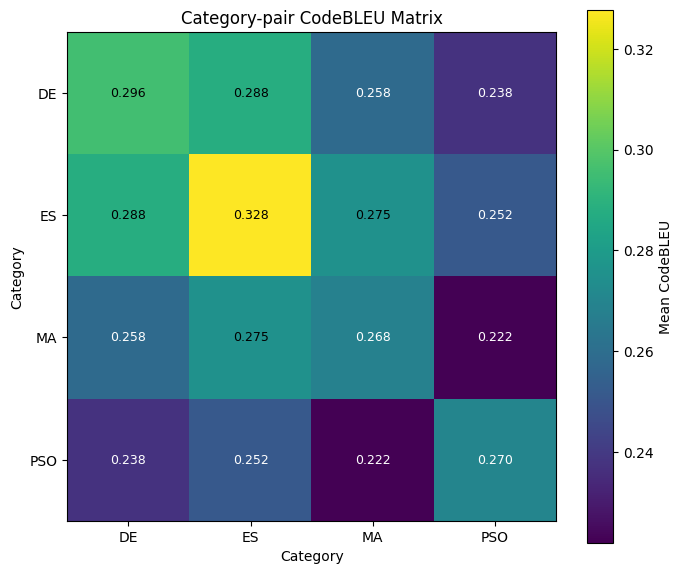

In [11]:
plt.figure(figsize=(7, 6))
plt.imshow(matrix.astype(float), interpolation="nearest")
plt.colorbar(label="Mean CodeBLEU")
plt.xticks(range(len(categories)), categories)
plt.yticks(range(len(categories)), categories)

vmin = np.nanmin(matrix.values.astype(float))
vmax = np.nanmax(matrix.values.astype(float))
threshold = vmin + 0.5 * (vmax - vmin)

for i, cat_a in enumerate(categories):
    for j, cat_b in enumerate(categories):
        value = matrix.loc[cat_a, cat_b]
        if not pd.isna(value):
            color = "white" if value < threshold else "black"
            plt.text(j, i, f"{value:.3f}", ha="center", va="center", fontsize=9, color=color)

plt.title("Category-pair CodeBLEU Matrix")
plt.xlabel("Category")
plt.ylabel("Category")
plt.tight_layout()
plt.show()

In [29]:
%pip install scikit-learn


  Using cached joblib-1.5.3-py3-none-any.whl.metadata (5.5 kB)
  Using cached threadpoolctl-3.6.0-py3-none-any.whl.metadata (13 kB)
   ---------------------------------------- 0.0/8.3 MB ? eta -:--:--
   ---------------- ----------------------- 3.4/8.3 MB 18.3 MB/s eta 0:00:01
   -------------------------------- ------- 6.8/8.3 MB 16.8 MB/s eta 0:00:01
   ---------------------------------------- 8.3/8.3 MB 16.0 MB/s  0:00:00
Using cached joblib-1.5.3-py3-none-any.whl (309 kB)
Using cached threadpoolctl-3.6.0-py3-none-any.whl (18 kB)

   ---------- ----------------------------- 1/4 [narwhals]
   ---------- ----------------------------- 1/4 [narwhals]
   ---------- ----------------------------- 1/4 [narwhals]
   ---------- ----------------------------- 1/4 [narwhals]
   ---------- ----------------------------- 1/4 [narwhals]
   ---------- ----------------------------- 1/4 [narwhals]
   ---------- ----------------------------- 1/4 [narwhals]
   ---------- ----------------------------- 1/4

In [2]:
import codebleu
from codebleu import calc_codebleu

result = calc_codebleu(
    references=["def add(a, b):\n    return a + b"],
    predictions=["def sum_values(x, y):\n    return x + y"],
    lang="python",
    weights=(0.25, 0.25, 0.25, 0.25),
)

print(result)

{'codebleu': 0.523297991032208, 'ngram_match_score': 0.043472087194499145, 'weighted_ngram_match_score': 0.04971987693433304, 'syntax_match_score': 1.0, 'dataflow_match_score': 1.0}
